# Data Integration and Cold-Chain Break Risk

**Final project – Data Integration and Strategic Foresight (Universidad EAFIT)** · Author: Sara Henao Fernández

> **Synthetic data.** Both datasets were generated with AI for the course. **AndesMed** and **Glacia Health Logistics** are fictional companies; any resemblance to real companies is coincidental.

**Context.** AndesMed distributes refrigerated medicines in Colombia. Every time the cold chain breaks (the temperature leaves the allowed range), the product can be lost. AndesMed has 1,500 days of its own history and wants to know whether it can complement it with data from an external operator, Glacia Health Logistics, before measuring its risk.

**Business questions**
1. Which part of the external data can be integrated without distorting AndesMed's reality?
2. How much does AndesMed lose on a typical day, and which frequency and severity scenarios explain it?
3. How much would the loss drop with different risk-management strategies?

**Methods:** integration through information hubs (Method 1), multidimensional integration by clusters (Method 2), credibility theory, and fuzzy-logic risk matrices (membership, loss, events and impact).

**Main results**
- Method 2 integrated 320 of 1,500 external records and preserved the original distribution (mean discrepancy ≈ 1.5–2.2%); Method 1 distorted it (≈ 16%).
- A typical day's loss is **62.3 million COP** with impact levels, versus 56.7 million with the traditional calculation.
- With medium management (levels 2 to 4) at level 1.5, the loss drops to 45.1 million (−28%).

The data files go in `data/`. The original datasets have Spanish column names and values; the notebook translates them to English when it loads them.

# Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns  #Statistical charts
import matplotlib.pyplot as plt
import random
import scipy.stats as stats
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None

from pathlib import Path

# 0. Description and preparation of the datasets

Both datasets were generated with AI and have the same structure (1,500 records and 9 columns), but different risk profiles: AndesMed is a national distributor with more breaks and lower losses per break; Glacia Health Logistics is a specialized global operator with fewer breaks, but higher-value cargo.

Each record is **one day of operation**. The original files use Spanish column names, which are translated when the data is loaded:

| Variable (original name) | Type | Description | Integration potential? |
|---|---|---|---|
| `ID` | Integer | Record number (repeats across both datasets) | No |
| `Date` (`Fecha`) | Date | Day of operation (2022-01-01 to 2026-02-08) | No (reference only) |
| `Vehicle_Type` (`Tipo_Vehiculo`) | Categorical | Main vehicle that day: refrigerated truck, refrigerated van or small refrigerated van | Yes (profiling) |
| `Route` (`Ruta`) | Categorical | Main route that day (6 national routes) | Yes (profiling) |
| `Main_Cause` (`Causa_Principal`) | Categorical | Main cause of that day's breaks | Yes (profiling) |
| `Break_Frequency` (`Frecuencia_Ruptura`) | Integer | Number of cold-chain breaks that day | **Yes (integration variable)** |
| `Severity_COP` (`Severidad_COP`) | Integer | Average cost of each break that day (COP) | **Yes (integration variable)** |
| `LDA` | Integer | Daily loss = Frequency × Severity (COP) | **Yes (integration variable)** |
| `Shipments` (`Envios`) | Integer | Number of refrigerated shipments that day | Yes (used to compute the break rate) |

In [2]:
def data_path(name):
    """Finds the file in ../data (Jupyter from notebooks/) or in data/ (Colab or the repo root)."""
    folders = (Path("../data"), Path("data"))
    for folder in folders:
        if (folder / name).exists():
            return folder / name
    for folder in folders:          # new file (for example, the integrated dataset): saved in data/
        if folder.is_dir():
            return folder / name
    return Path(name)

#The original files have Spanish column names and values: they're translated on load
COLUMNS = {'Fecha':'Date','Tipo_Vehiculo':'Vehicle_Type','Ruta':'Route','Causa_Principal':'Main_Cause',
           'Frecuencia_Ruptura':'Break_Frequency','Severidad_COP':'Severity_COP','Envios':'Shipments'}
VEHICLES = {'Camión refrigerado':'Refrigerated truck','Furgón refrigerado':'Refrigerated van',
            'Van refrigerada':'Small refrigerated van'}
CAUSES = {'Error operativo':'Operational error','Apertura prolongada de puertas':'Doors left open too long',
          'Retraso en ruta':'Route delay','Falla del sensor':'Sensor failure',
          'Falla de refrigeración':'Refrigeration failure','Falla eléctrica':'Electrical failure'}

def load(df):
    df = df.rename(columns=COLUMNS)
    df['Vehicle_Type'] = df['Vehicle_Type'].replace(VEHICLES)
    df['Main_Cause'] = df['Main_Cause'].replace(CAUSES)
    return df

nxl=data_path('DF_AndesMed_Cold_Chain_LDA_v2.csv')
nxle=data_path('DF_Glacia_Health_external_data_v2.xlsx')

XDB=load(pd.read_csv(nxl))      #Internal data: AndesMed
XDE=load(pd.read_excel(nxle))   #External data: Glacia Health Logistics
display(XDB.head())
display(XDE.head())

print("AndesMed records:" ,len(XDB) ,"- Glacia records:" ,len(XDE))
print("Missing values AndesMed:" ,XDB.isna().sum().sum() ,"- Missing values Glacia:" ,XDE.isna().sum().sum())
display(XDB.iloc[:,[5,6,7]].describe())
display(XDE.iloc[:,[5,6,7]].describe())

for col in ['Vehicle_Type','Route','Main_Cause']:
  print("----------------------")
  print("AndesMed:\n" ,XDB[col].value_counts())
  print("Glacia:\n" ,XDE[col].value_counts())

#Break rate: what percentage of shipments had a cold-chain break
print("----------------------")
print("AndesMed break rate (%):" ,np.mean(XDB.iloc[:,5]/XDB.iloc[:,8])*100)
print("Glacia break rate (%):" ,np.mean(XDE.iloc[:,5]/XDE.iloc[:,8])*100)

,ID,Date,Vehicle_Type,Route,Main_Cause,Break_Frequency,Severity_COP,LDA,Shipments
0,1,2022-01-01,Refrigerated van,Medellín-Bucaramanga,Doors left open too long,5,1176892,5884460,413
1,2,2022-01-02,Refrigerated truck,Bogotá-Cali,Electrical failure,5,2717712,13588560,249
2,3,2022-01-03,Small refrigerated van,Medellín-Bucaramanga,Sensor failure,46,875536,40274656,767
3,4,2022-01-04,Refrigerated van,Bogotá-Barranquilla,Operational error,31,1673472,51877632,710
4,5,2022-01-05,Refrigerated truck,Bogotá-Cali,Doors left open too long,21,1368840,28745640,647


,ID,Date,Vehicle_Type,Route,Main_Cause,Break_Frequency,Severity_COP,LDA,Shipments
0,1,2022-01-01,Refrigerated truck,Bogotá-Barranquilla,Doors left open too long,14,3299876,46198264,918
1,2,2022-01-02,Refrigerated van,Medellín-Bucaramanga,Refrigeration failure,7,7018050,49126350,590
2,3,2022-01-03,Small refrigerated van,Medellín-Bucaramanga,Sensor failure,29,2279992,66119768,1585
3,4,2022-01-04,Refrigerated van,Cali-Pereira,Refrigeration failure,13,8377432,108906616,1341
4,5,2022-01-05,Refrigerated van,Cali-Pereira,Refrigeration failure,22,4834736,106364192,1369


AndesMed records: 1500 - Glacia records: 1500
Missing values AndesMed: 0 - Missing values Glacia: 0


,Break_Frequency,Severity_COP,LDA
count,1500.00000,1.500000e+03,1.500000e+03
mean,27.48200,2.079174e+06,5.469273e+07
std,15.87124,1.641410e+06,4.526139e+07
min,1.00000,3.870680e+05,1.058328e+06
25%,16.00000,1.220516e+06,2.509149e+07
50%,25.00000,1.696787e+06,4.301809e+07
75%,36.00000,2.429733e+06,7.017002e+07
max,133.00000,4.023175e+07,4.365075e+08


,Break_Frequency,Severity_COP,LDA
count,1500.000000,1.500000e+03,1.500000e+03
mean,13.840000,5.397140e+06,7.216678e+07
std,8.938811,4.453939e+06,6.996337e+07
min,1.000000,6.603020e+05,6.603020e+05
25%,7.000000,2.999364e+06,2.851548e+07
50%,12.000000,4.399685e+06,5.460753e+07
75%,18.000000,6.567628e+06,9.343677e+07
max,99.000000,8.022515e+07,6.836161e+08


----------------------
AndesMed:
 Vehicle_Type
Refrigerated truck        650
Refrigerated van          555
Small refrigerated van    295
Name: count, dtype: int64
Glacia:
 Vehicle_Type
Refrigerated truck        830
Refrigerated van          431
Small refrigerated van    239
Name: count, dtype: int64
----------------------
AndesMed:
 Route
Medellín-Bogotá         348
Medellín-Bucaramanga    294
Medellín-Cali           239
Bogotá-Barranquilla     221
Bogotá-Cali             205
Cali-Pereira            193
Name: count, dtype: int64
Glacia:
 Route
Medellín-Bogotá         367
Bogotá-Barranquilla     341
Bogotá-Cali             321
Medellín-Cali           179
Cali-Pereira            158
Medellín-Bucaramanga    134
Name: count, dtype: int64
----------------------
AndesMed:
 Main_Cause
Operational error           440
Doors left open too long    300
Route delay                 291
Sensor failure              174
Refrigeration failure       165
Electrical failure          130
Name: count, dtype:

**Adjustments to the datasets before integrating:**
- The date is text in AndesMed and a date in Glacia: it's unified.
- The ID repeats across both datasets: a Source column is added.
- Severity and loss are converted to **millions of COP (MCOP)**.

In [3]:
XDB['Date']=pd.to_datetime(XDB['Date'])
XDB['Source']='AndesMed'
XDE['Source']='Glacia'

# 1. Method 1 – Integration through information hubs (Monte Carlo)

The mean of the internal data is (MCOP): 54.692734949999995
The skewness coefficient is: 2.479948999722072
The kurtosis coefficient is: 10.042872355728868


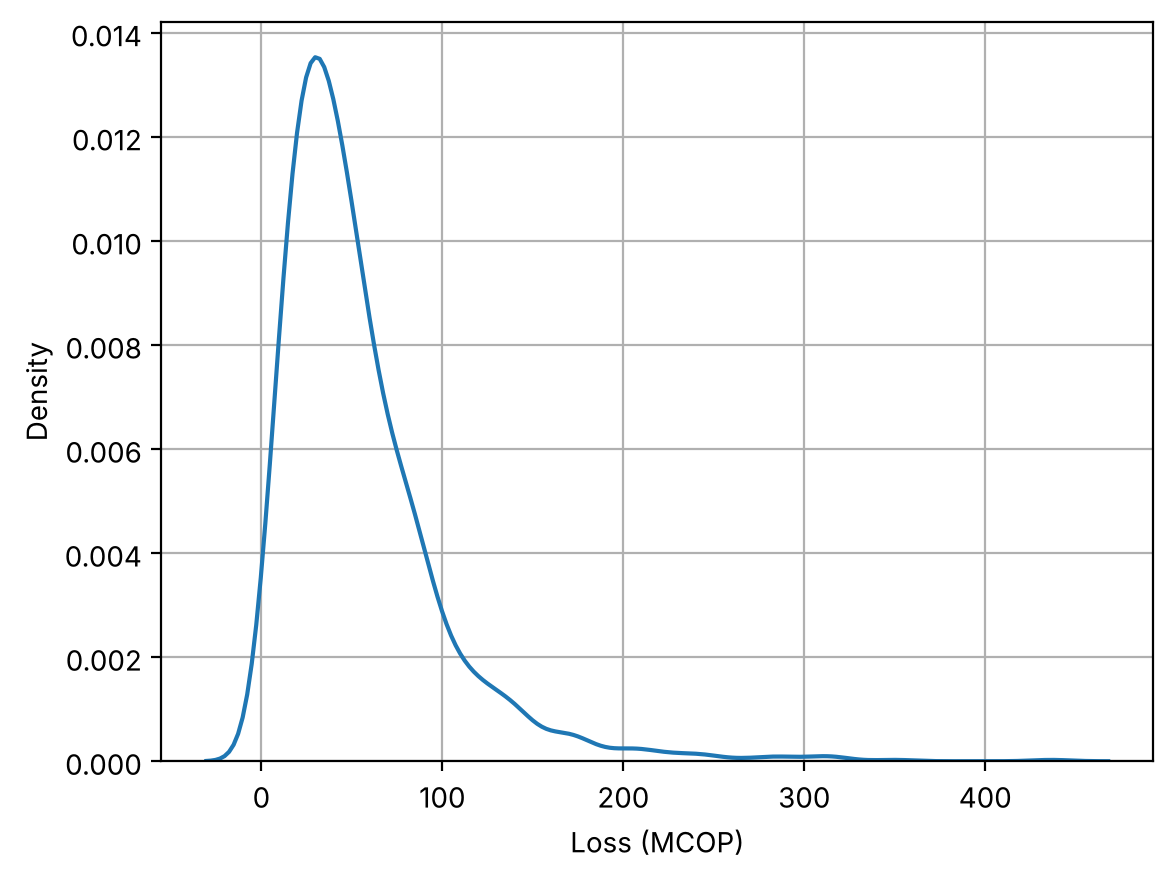

In [4]:
Freq=XDB.iloc[:,5]; Sev=XDB.iloc[:,6]/1e6
LDA=Freq*Sev   #AndesMed loss (MCOP)

print("The mean of the internal data is (MCOP):" ,np.mean(LDA))
print("The skewness coefficient is:" ,LDA.skew())
print("The kurtosis coefficient is:" ,LDA.kurtosis())

plt.figure()
sns.kdeplot(LDA)
plt.xlabel('Loss (MCOP)')
plt.grid()
plt.show()

## 1.2 Number of hubs: elbow method and silhouette score

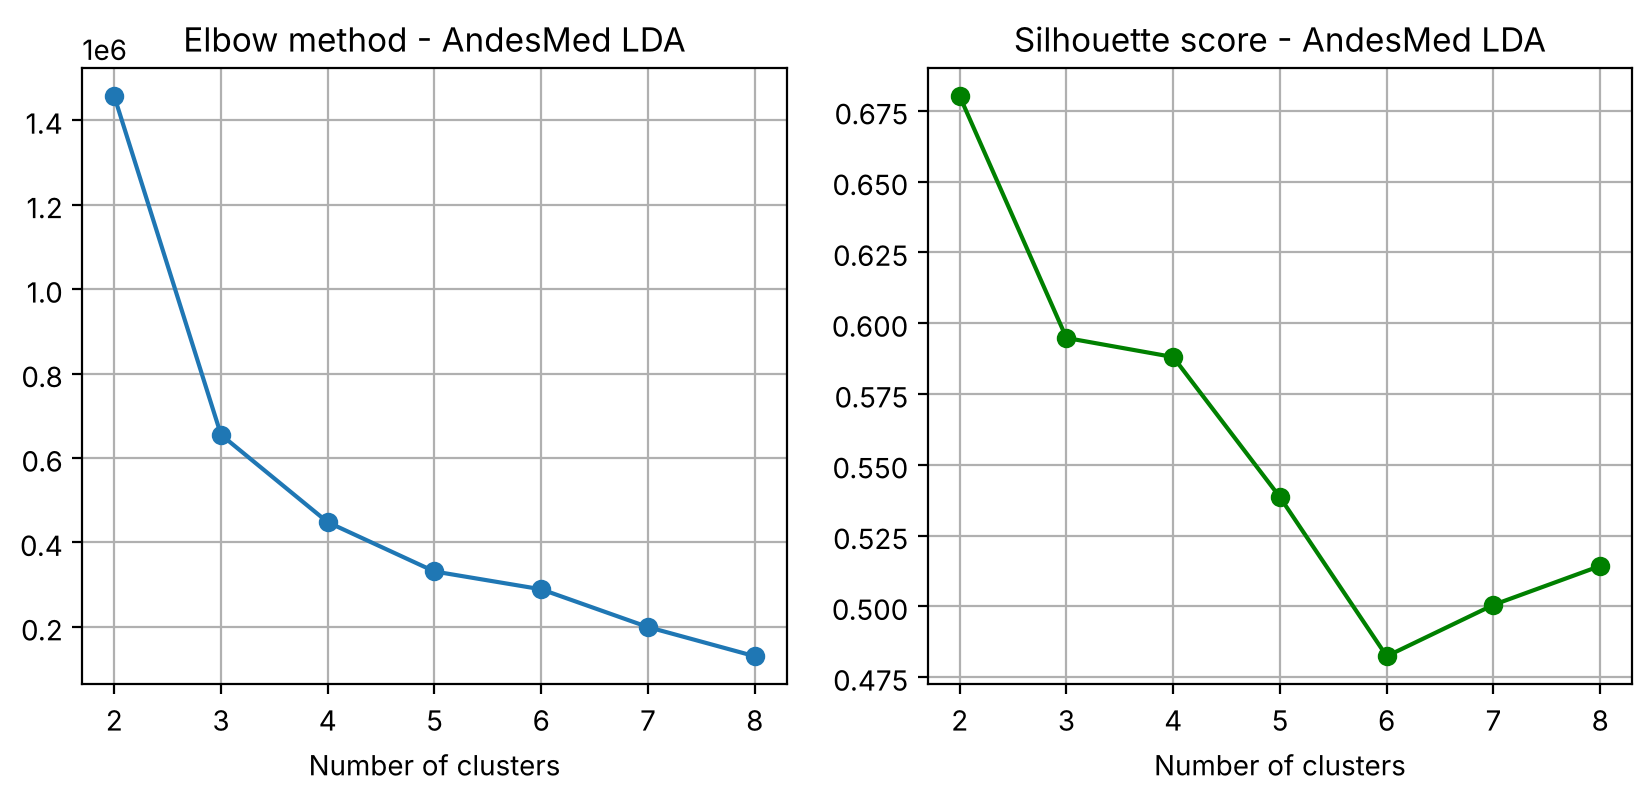

K = 2 - Inertia: 1456874.8 - Silhouette: 0.68
K = 3 - Inertia: 655088.1 - Reduction vs. previous K: 801786.7 - Silhouette: 0.595
K = 4 - Inertia: 447877.6 - Reduction vs. previous K: 207210.4 - Silhouette: 0.588
K = 5 - Inertia: 331230.6 - Reduction vs. previous K: 116647.0 - Silhouette: 0.539
K = 6 - Inertia: 288998.1 - Reduction vs. previous K: 42232.6 - Silhouette: 0.482
K = 7 - Inertia: 199510.3 - Reduction vs. previous K: 89487.7 - Silhouette: 0.501
K = 8 - Inertia: 130503.4 - Reduction vs. previous K: 69006.9 - Silhouette: 0.514


In [5]:
def clustering(Xi,K=5):

  Xi=np.array(Xi).astype(float) #Keeps the average from being truncated when the data are integers

  #Clustering process
  XC=np.random.choice(Xi,size=K,replace=False)  #replace=False: avoids using the same value twice as a seed
  XC=np.sort(XC)
  nc=np.zeros((len(Xi),1))

  for k in range(len(Xi)):
    d=np.abs(XC-Xi[k])
    nc[k]=np.argmin(d)
    nc2=np.int32(nc[k])
    XC[nc2,]=(XC[nc2,]+Xi[k])/2  #Moves the center to the midpoint (dynamic k-means)

  #The seeds are sorted and the data reassigned
  XC=np.sort(XC)
  for k in range(len(Xi)):
    d=np.abs(XC-Xi[k])
    nc[k]=np.argmin(d)

  return XC,nc

def elbow_silhouette(Xi,name):
  Xi=np.array(Xi).astype(float)
  Ks=range(2,9)
  W=[]; S=[]
  for K in Ks:
    np.random.seed(42)
    XC,nc=clustering(Xi,K)
    lab=nc[:,0].astype(int)
    W.append(np.sum((Xi-XC[lab])**2))                #Inertia (elbow)
    S.append(silhouette_score(Xi.reshape(-1,1),lab))  #reshape: silhouette needs the data as a column

  plt.figure(figsize=(10,4))
  plt.subplot(1,2,1)
  plt.plot(Ks,W,marker='o')
  plt.title(f'Elbow method - {name}')
  plt.xlabel('Number of clusters'); plt.grid()
  plt.subplot(1,2,2)
  plt.plot(Ks,S,marker='o',color='green')
  plt.title(f'Silhouette score - {name}')
  plt.xlabel('Number of clusters'); plt.grid()
  plt.show()

  for i in range(len(Ks)):
    if i==0:
      print("K =" ,Ks[i] ,"- Inertia:" ,round(W[i],1) ,"- Silhouette:" ,round(S[i],3))
    else:
      print("K =" ,Ks[i] ,"- Inertia:" ,round(W[i],1) ,"- Reduction vs. previous K:" ,round(W[i-1]-W[i],1) ,"- Silhouette:" ,round(S[i],3))

  return W,S

W1,S1=elbow_silhouette(LDA,'AndesMed LDA')

**Number of clusters:** inertia drops sharply up to K = 5: going from 4 to 5 clusters still reduces it by 116,647, while going from 5 to 6 only reduces it by 42,233. That puts the elbow at 5.

The silhouette score is highest with 2 clusters (0.68), but two groups would only split losses into low and high, which isn't enough to characterize the risk. K = 4 has a slightly higher silhouette than K = 5 (0.588 vs. 0.539), but both are above 0.5, and going from 4 to 5 still improves inertia a lot. Five clusters are also consistent with the 5 levels of the risk matrices. So the analysis uses **K = 5 information hubs**.

## 1.3 Creating the information hubs

In [6]:
K=5  #Number of hubs selected with the elbow and silhouette (section 1.2)
print("Number of hubs selected:" ,K)
print("Inertia with K =" ,K ,":" ,W1[K-2] ,"- Silhouette with K =" ,K ,":" ,S1[K-2])  #W1 and S1 start at K = 2

random.seed(42)
XC=np.array(random.choices(list(LDA),k=K))
XC=np.sort(XC)
print("The information hubs are:" ,XC)

Number of hubs selected: 5
Inertia with K = 5 : 331230.61061316583 - Silhouette with K = 5 : 0.5385374386708296
The information hubs are: [17.495406 28.686096 46.018056 50.859    51.62598 ]


## 1.4 Classifying the data by information hub
Each box stores the **position of the record** (not only its LDA value), so the integrated dataset keeps every column.

In [7]:
Boxes=[]
for j in range(K):
  Boxes.append([])  #One empty box per hub

for k in range(len(LDA)):
  d=np.abs(XC-LDA.iloc[k,])/XC  #Distance from a data point to each hub
  nc=np.argmin(d)               #Number of the box where the data point goes
  XC[nc,]=(XC[nc,]+LDA.iloc[k,])/2
  Boxes[nc].append(k)           #Position of the internal record

#Percentage of data in each box
pm=[]
for j in range(K):
  pj=len(Boxes[j])/len(LDA)
  pm.append(pj)

pm=(np.array(pm)*1000).astype(int)
pm[np.argmax(pm)]=pm[np.argmax(pm)]+(1000-np.sum(pm))  #Adjustment so they add up to exactly 1000
print("The final hubs are:" ,XC)
print("Records to sample per box:" ,pm ,"- Total:" ,np.sum(pm))

#Profile of each box
minimum=[];maximum=[];mean=[]
for j in range(K):
  minimum.append(np.min(LDA.iloc[Boxes[j]])); maximum.append(np.max(LDA.iloc[Boxes[j]])); mean.append(np.mean(LDA.iloc[Boxes[j]]))
TC1=pd.DataFrame({'Hub (MCOP)':XC,'Internal records':[len(b) for b in Boxes],
                  'Minimum (MCOP)':minimum,'Maximum (MCOP)':maximum,'Mean (MCOP)':mean,'Sample (of 1000)':pm})
display(TC1)

The final hubs are: [  2.80250286   5.61193749  15.61265894  29.71913778 151.21840014]
Records to sample per box: [ 23  64 152 344 417] - Total: 1000


,Hub (MCOP),Internal records,Minimum (MCOP),Maximum (MCOP),Mean (MCOP),Sample (of 1000)
0,2.802503,35,1.058328,15.963059,6.395879,23
1,5.611937,97,4.995480,28.745640,12.172599,64
2,15.612659,228,7.686777,45.833952,20.872887,152
3,29.719138,517,16.275610,75.390852,37.463065,344
4,151.218400,623,30.713690,436.507533,90.701576,417


## 1.5 Sampling by box to create LDA2 (internal data only)
Before integrating, we check that sampling 1,000 records reproduces the original distribution.

The mean of the observed data is (MCOP): 54.692734949999995
The mean of the sampled data is (MCOP): 55.564889986
The relative error in percent is: 1.59464513302786


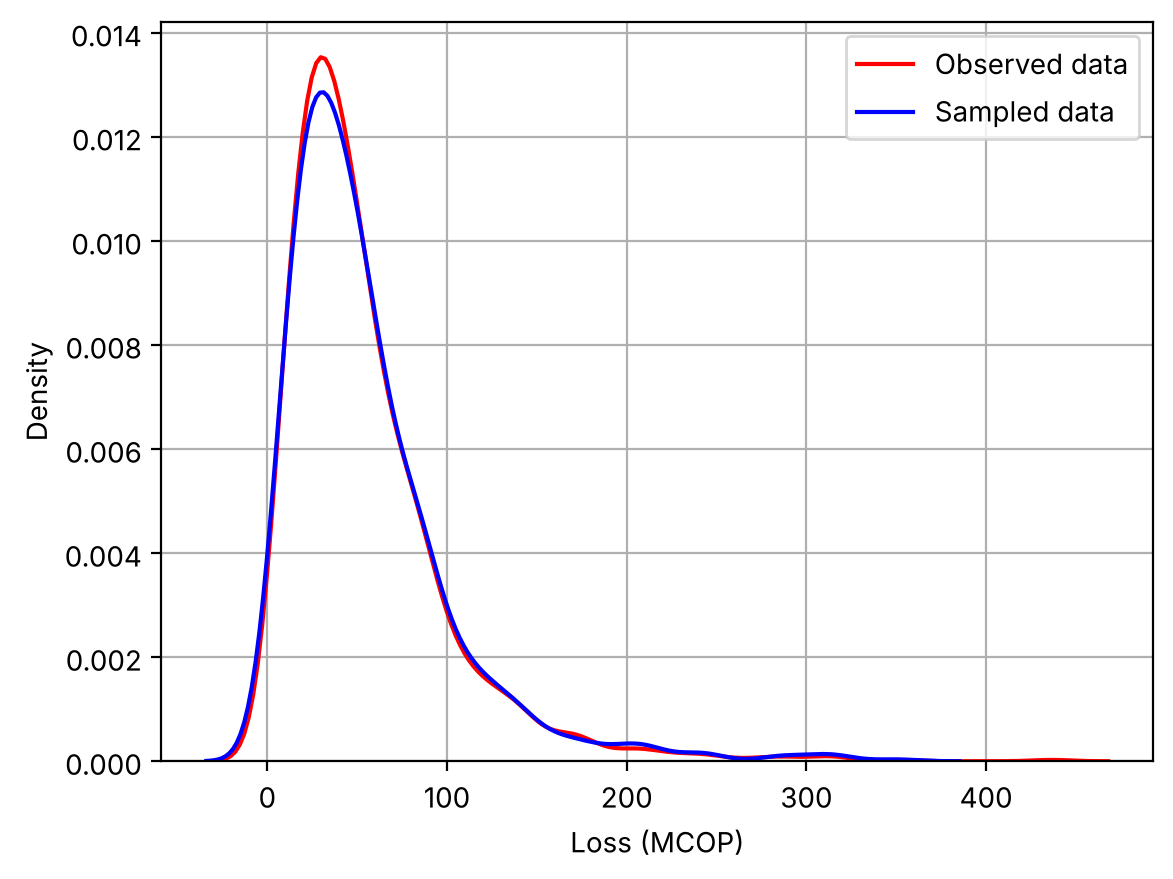

In [8]:
random.seed(42)
LDA2=[]
for j in range(K):
  LDA2.extend(LDA.iloc[random.sample(Boxes[j],k=pm[j])])  #sample: without repeating records
LDA2=np.array(LDA2)

uo=np.mean(LDA)
print("The mean of the observed data is (MCOP):" ,uo)
ue=np.mean(LDA2)
print("The mean of the sampled data is (MCOP):" ,ue)
du=np.abs((uo-ue)/uo)
print("The relative error in percent is:" ,du*100)

plt.figure()
sns.kdeplot(LDA,color='red',label='Observed data')
sns.kdeplot(LDA2,color='blue',label='Sampled data')
plt.xlabel('Loss (MCOP)')
plt.legend()
plt.grid()
plt.show()

## 1.6 Integrating the Glacia data (external data)

The mean of the external data is (MCOP): 72.16678315933333
The skewness coefficient is: 3.176079465879511
The kurtosis coefficient is: 16.77229397664151


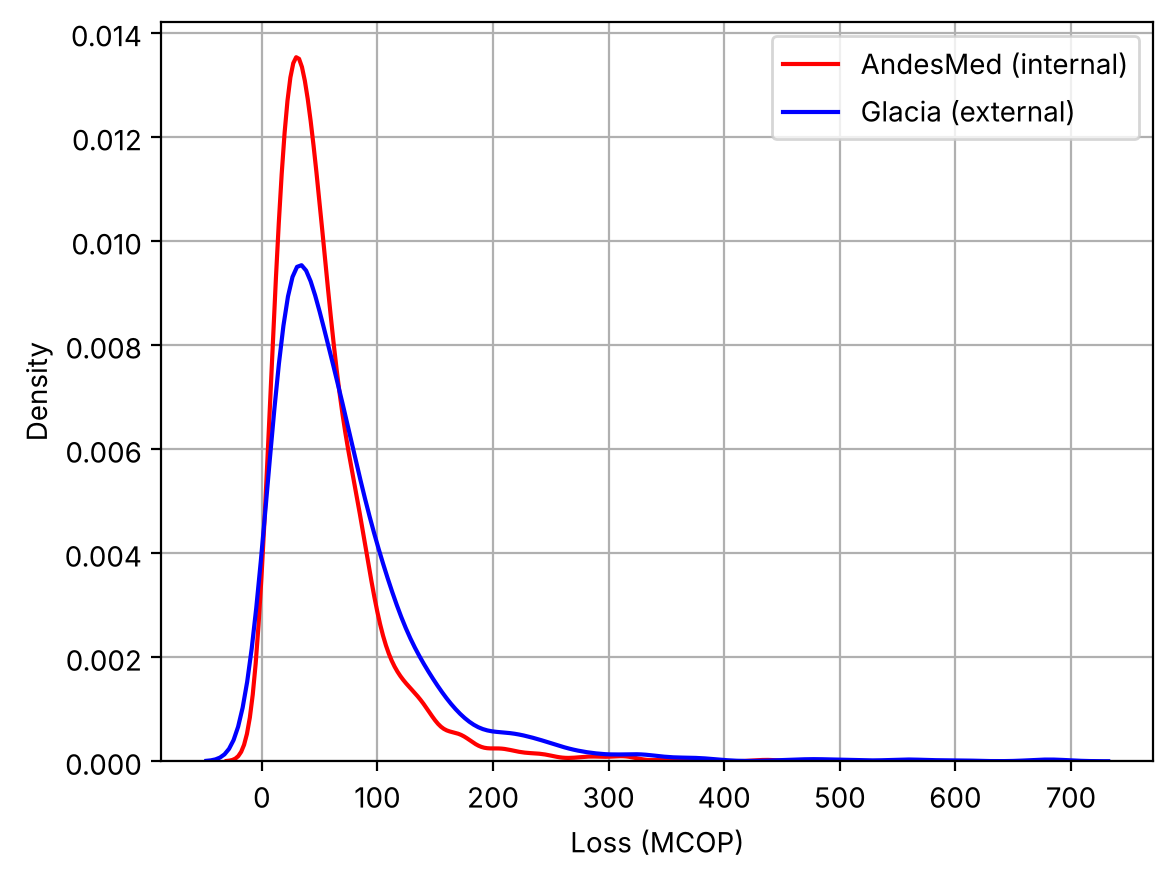

In [9]:
Freqe=XDE.iloc[:,5]; Seve=XDE.iloc[:,6]/1e6
LDAe=Freqe*Seve
print("The mean of the external data is (MCOP):" ,np.mean(LDAe))
print("The skewness coefficient is:" ,LDAe.skew())
print("The kurtosis coefficient is:" ,LDAe.kurtosis())

plt.figure()
sns.kdeplot(LDA,color='red',label='AndesMed (internal)')
sns.kdeplot(LDAe,color='blue',label='Glacia (external)')
plt.xlabel('Loss (MCOP)')
plt.legend()
plt.grid()
plt.show()

### 1.6.1 Integrating the external data
A Glacia record is integrated only if its membership in some box is greater than 0.9.

Records integrated: 859 of 1500
Records rejected: 641


,Glacia LDA (MCOP),Maximum membership,Assigned box,Decision
0,46.198264,0.857501,-1,Rejected
1,49.126350,0.807980,-1,Rejected
2,66.119768,0.853555,-1,Rejected
3,108.906616,0.961611,4,Integrated
4,106.364192,0.983537,4,Integrated
5,199.361169,0.790090,-1,Rejected
6,75.551874,0.936956,4,Integrated
7,34.398588,0.987680,3,Integrated
8,15.326598,0.999832,2,Integrated
9,65.664081,0.949408,4,Integrated


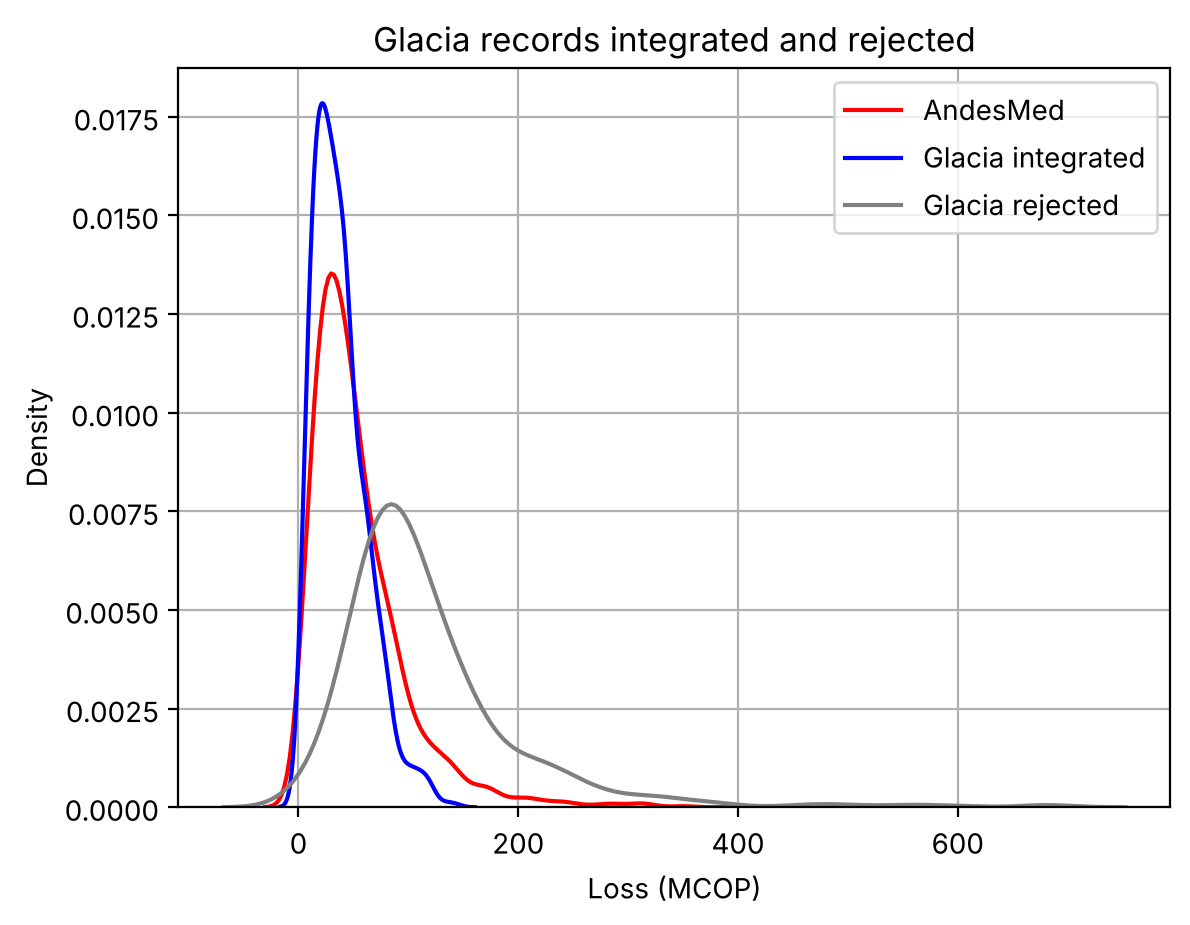

In [10]:
LDAe=np.array(LDAe)
m1=0       #How many records have been integrated
VPmax=[]   #Maximum membership of each external record
boxe=[]    #Box it's integrated into (-1 if rejected)

for k in range(len(LDAe)):
  VP=np.exp(-0.5*((XC-LDAe[k,])/XC)**2)  #Which box the data point belongs to
  VPmax.append(np.max(VP))
  if np.max(VP)>0.9:
    m1=m1+1
    nc=np.argmax(VP)
    Boxes[nc].append(len(LDA)+k)  #Position of the external record in the combined dataset
    XC[nc,]=(XC[nc,]+LDAe[k,])/2
    boxe.append(nc)
  else:
    boxe.append(-1)
boxe=np.array(boxe)

print("Records integrated:" ,m1 ,"of" ,len(LDAe))
print("Records rejected:" ,len(LDAe)-m1)

#How each external record was decided (first 10)
dfe1=pd.DataFrame({'Glacia LDA (MCOP)':LDAe,'Maximum membership':VPmax,'Assigned box':boxe})
dfe1['Decision']=np.where(boxe>=0,'Integrated','Rejected')
display(dfe1.head(10))

plt.figure()
sns.kdeplot(LDA,color='red',label='AndesMed')
sns.kdeplot(LDAe[boxe>=0],color='blue',label='Glacia integrated')
sns.kdeplot(LDAe[boxe<0],color='gray',label='Glacia rejected')
plt.xlabel('Loss (MCOP)')
plt.title('Glacia records integrated and rejected')
plt.legend()
plt.grid()
plt.show()

### 1.6.2 Sampling the boxes (1,000 records)

,AndesMed in the box,Glacia integrated,AndesMed sample,Glacia sample,Total sample
0,35,10,17,6,23
1,97,20,54,10,64
2,228,91,104,48,152
3,517,242,235,109,344
4,623,496,228,189,417


Records in the integrated dataset (Method 1): 1000
Source
AndesMed    638
Glacia      362
Name: count, dtype: int64


,ID,Date,Vehicle_Type,Route,Main_Cause,Break_Frequency,Severity_COP,LDA,Shipments,Source
0,1108,2025-01-12,Refrigerated truck,Bogotá-Barranquilla,Doors left open too long,1,3198006,3198006,571,Glacia
1,44,2022-02-13,Refrigerated truck,Cali-Pereira,Route delay,2,1689047,3378094,256,AndesMed
2,2,2022-01-02,Refrigerated truck,Bogotá-Cali,Electrical failure,5,2717712,13588560,249,AndesMed
3,163,2022-06-12,Refrigerated van,Medellín-Cali,Doors left open too long,8,821458,6571664,278,AndesMed
4,122,2022-05-02,Refrigerated van,Cali-Pereira,Route delay,3,914733,2744199,507,AndesMed


The mean of the data is: 54.692734949999995
The mean of the sampled data is: 55.564889986
The mean of the sampled data with the external data is: 46.01117948200001
The skewness coefficient for LDA is: 2.4774683615259807
The skewness coefficient for LDA2 is: 2.3284213485849135
The skewness coefficient for LDA2e is: 3.1455638770572003


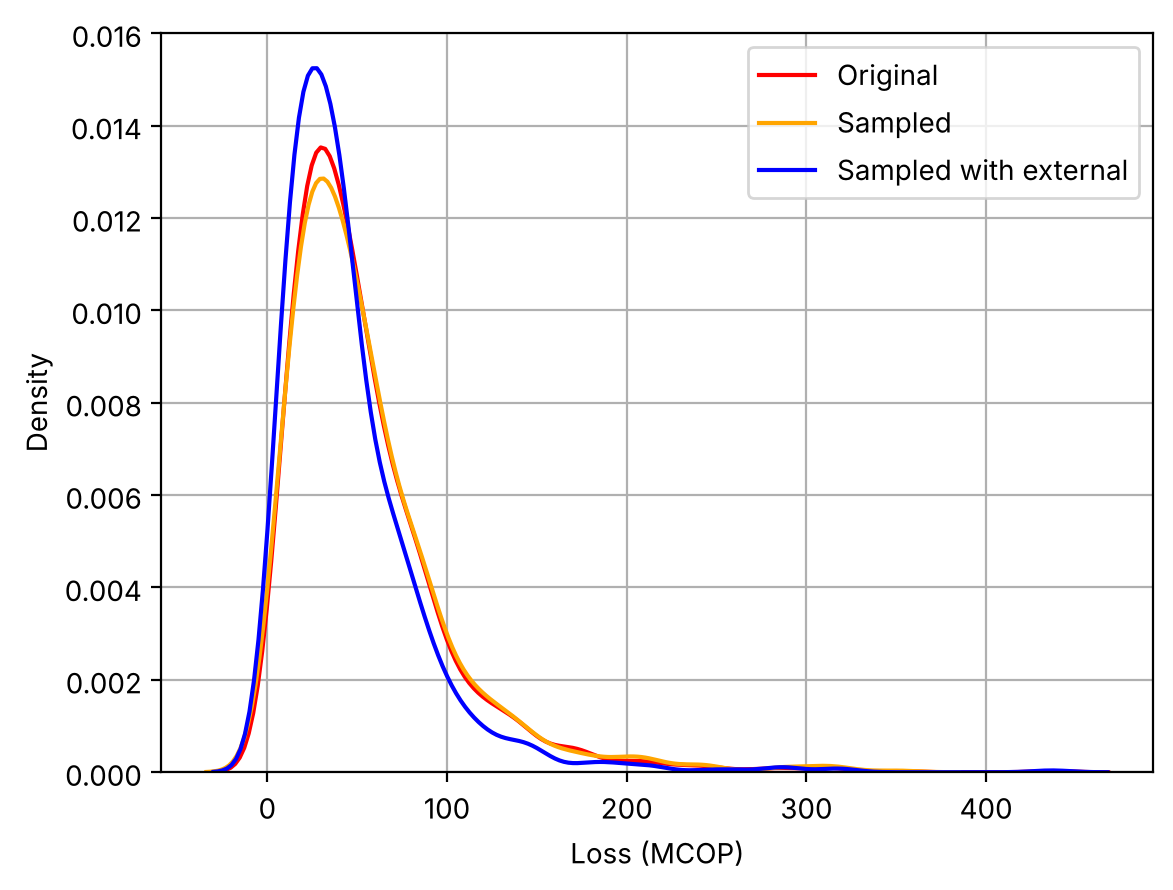

In [11]:
XT=pd.concat([XDB,XDE],ignore_index=True)  #Combined dataset: AndesMed (0-1499) + Glacia (1500-2999)

random.seed(42)
rows1=[]; sample1=[]
for j in range(K):
  sample1.append(random.sample(Boxes[j],k=pm[j]))
  rows1.extend(sample1[j])

#Sampling detail by box
cint=[];cext=[];mint=[];mext=[]
for j in range(K):
  b=np.array(Boxes[j]); m=np.array(sample1[j])
  cint.append(np.sum(b<len(LDA))); cext.append(np.sum(b>=len(LDA)))
  mint.append(np.sum(m<len(LDA))); mext.append(np.sum(m>=len(LDA)))
TB1=pd.DataFrame({'AndesMed in the box':cint,'Glacia integrated':cext,'AndesMed sample':mint,'Glacia sample':mext,'Total sample':pm})
display(TB1)

XDB1=XT.iloc[rows1,:].reset_index(drop=True)  #Integrated dataset - Method 1
LDA2e=np.array(XDB1.iloc[:,5]*XDB1.iloc[:,6]/1e6)

print("Records in the integrated dataset (Method 1):" ,len(XDB1))
print(XDB1['Source'].value_counts())
display(XDB1.head())

print("The mean of the data is:" ,np.mean(LDA))
print("The mean of the sampled data is:" ,np.mean(LDA2))
print("The mean of the sampled data with the external data is:" ,np.mean(LDA2e))
print("The skewness coefficient for LDA is:" ,stats.skew(LDA))
print("The skewness coefficient for LDA2 is:" ,stats.skew(LDA2))
print("The skewness coefficient for LDA2e is:" ,stats.skew(LDA2e))

plt.figure()
sns.kdeplot(LDA,color='red',label='Original')
sns.kdeplot(LDA2,color='orange',label='Sampled')
sns.kdeplot(LDA2e,color='blue',label='Sampled with external')
plt.xlabel('Loss (MCOP)')
plt.legend()
plt.grid()
plt.show()

### 1.6.3 Characterizing the distributions

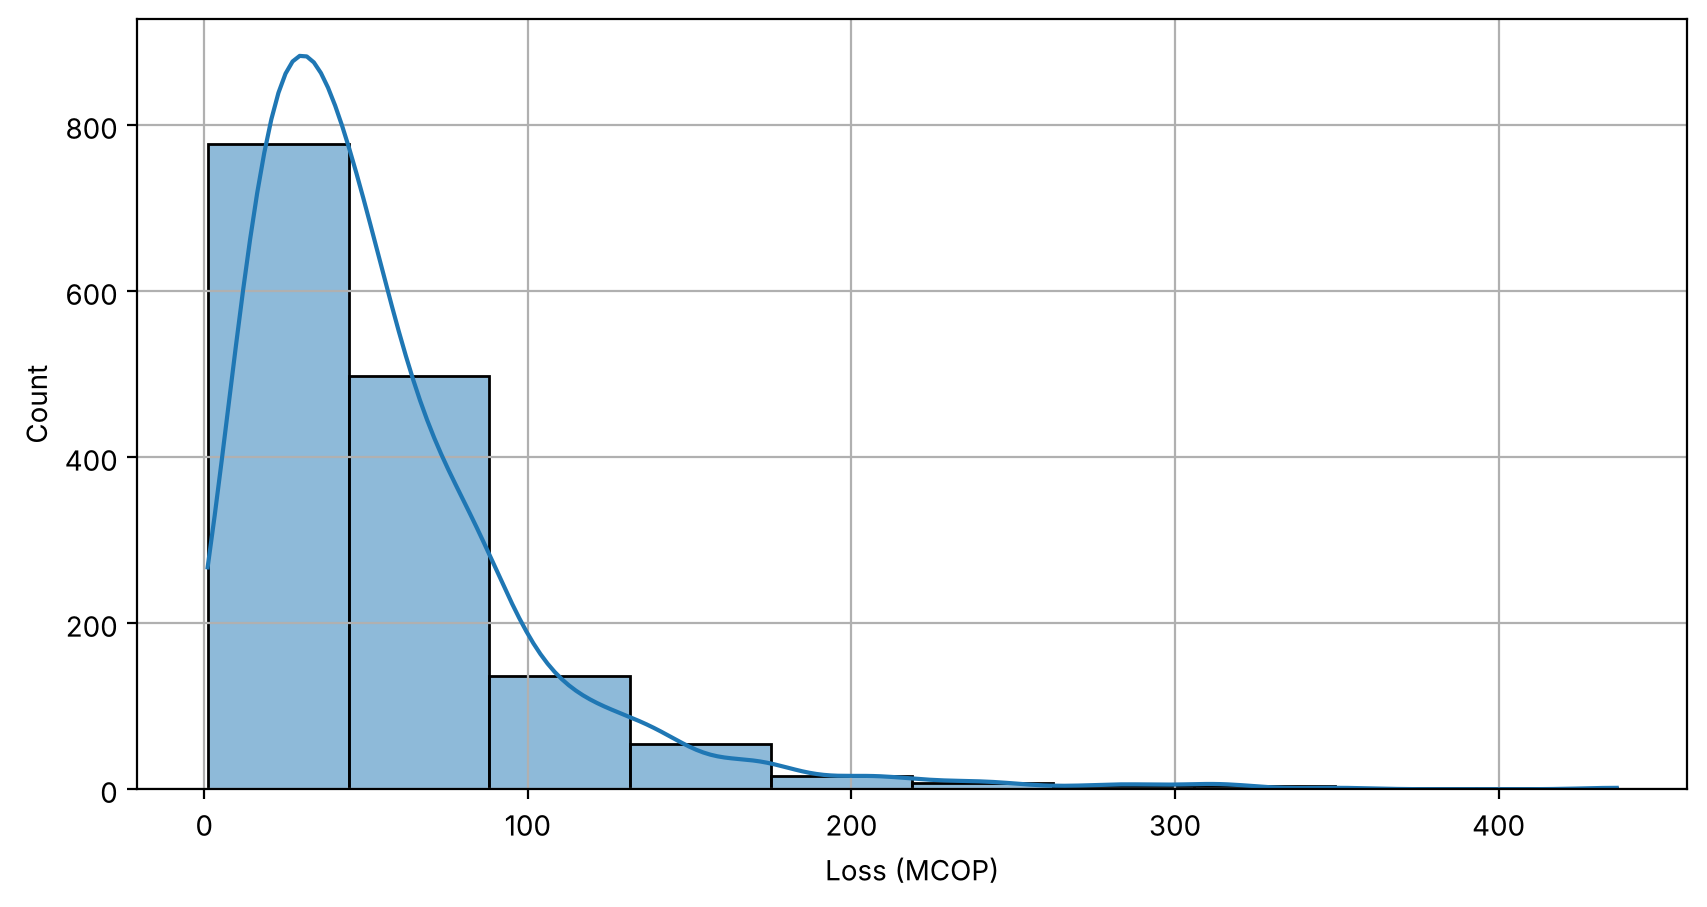

Original distribution - mean: 54.966939579000005 - skewness: 2.461799476078564 - kurtosis: 9.636392549648225


,Lower limit,Upper limit,Class mark,Count
0,1.058328,44.603249,22.830788,777.0
1,44.603249,88.148169,66.375709,498.0
2,88.148169,131.693090,109.920629,137.0
3,131.693090,175.238010,153.465550,54.0
4,175.238010,218.782930,197.010470,16.0
5,218.782930,262.327851,240.555391,8.0
6,262.327851,305.872772,284.100311,4.0
7,305.872772,349.417692,327.645232,4.0
8,349.417692,392.962613,371.190152,1.0
9,392.962613,436.507533,414.735073,1.0


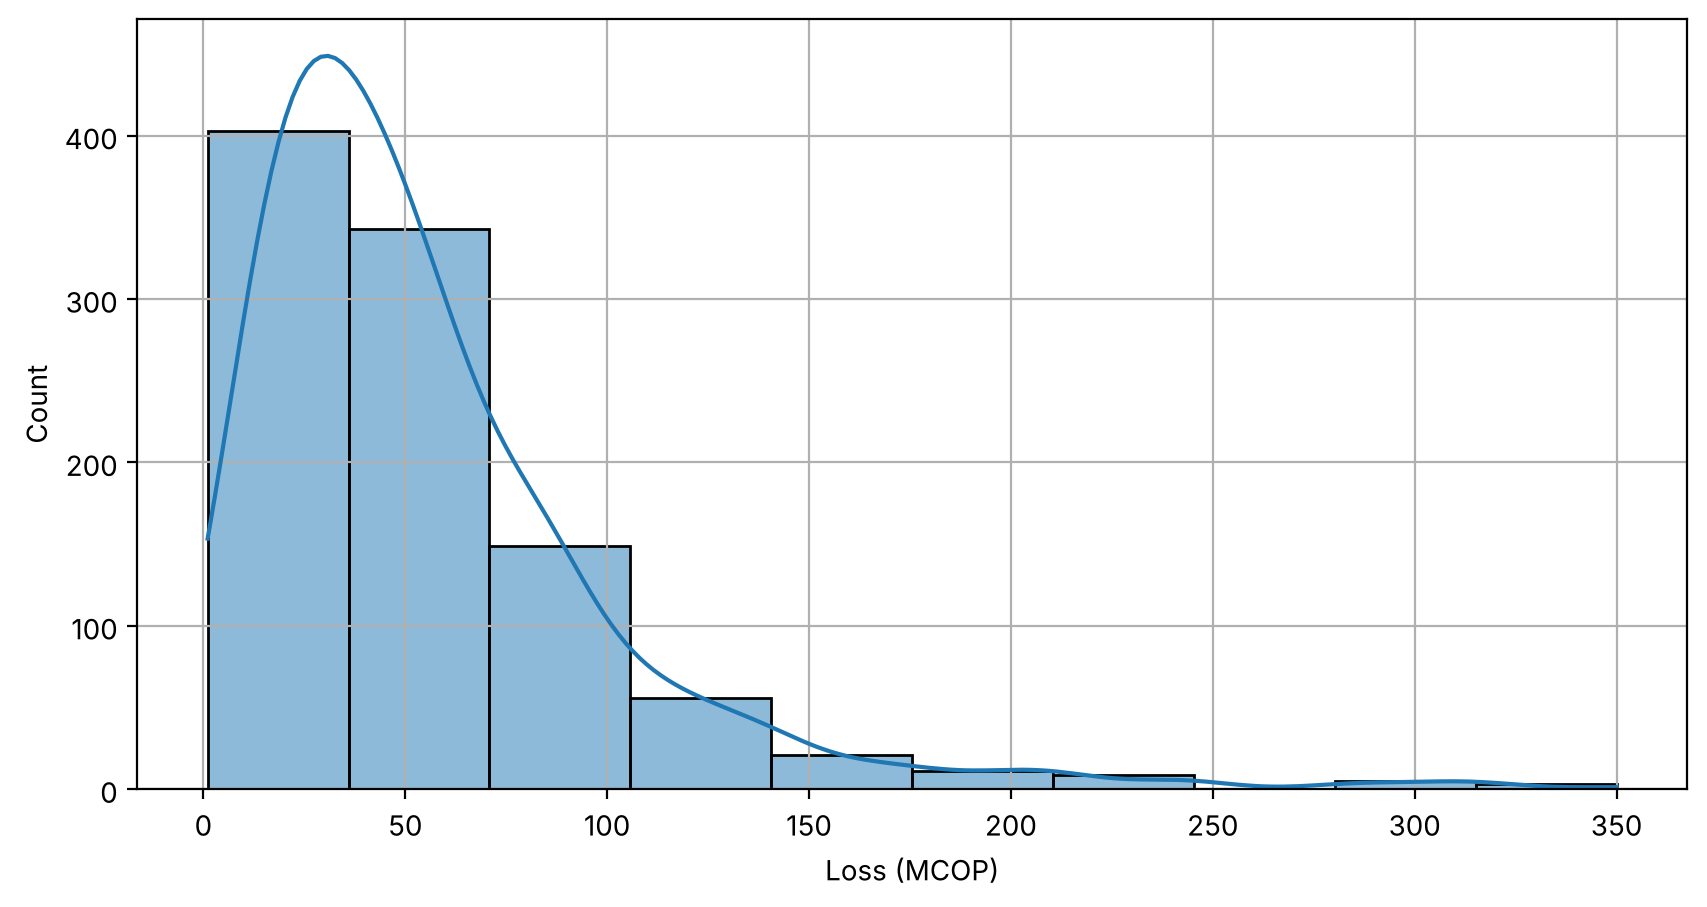

Sampled distribution - mean: 55.813966239 - skewness: 2.267733504624856 - kurtosis: 7.6140668269096725
The mean discrepancy is (%): 1.5409747504363551


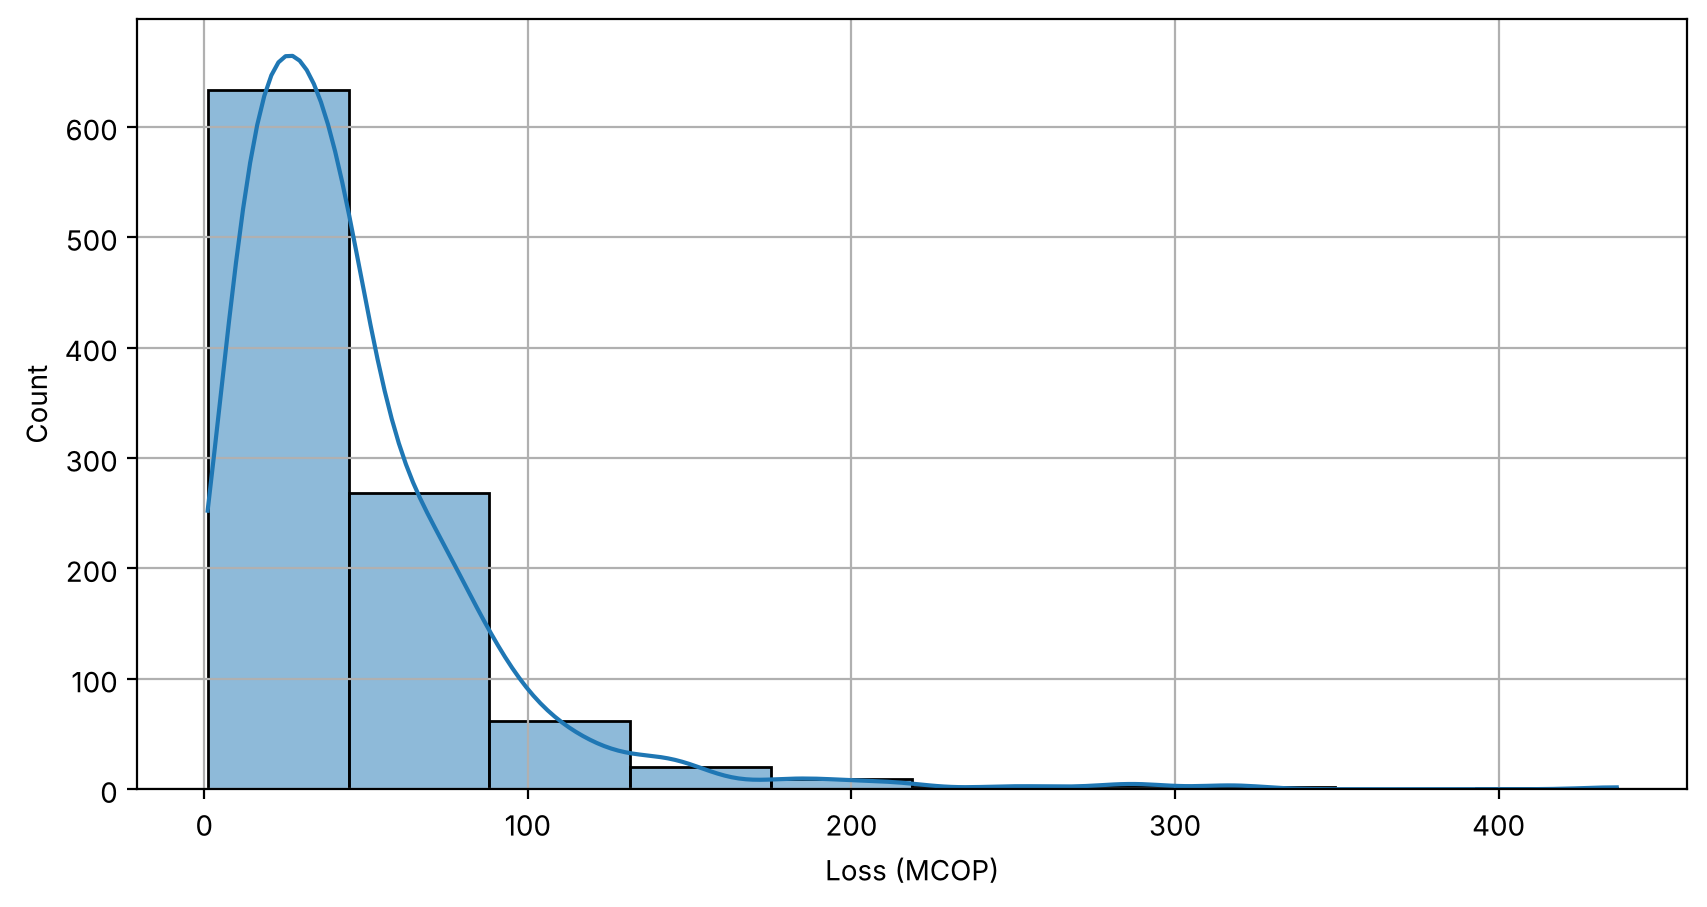

Distribution integrated with Glacia - mean: 46.3015003995 - skewness: 3.1186520644913687 - kurtosis: 15.379379683171923
The mean discrepancy is (%): 15.764820173489552


In [12]:
def characterize(LDA):

  plt.figure(figsize=(10,5))
  sns.histplot(LDA,bins=10,kde=True)
  plt.xlabel("Loss (MCOP)")
  plt.grid()
  plt.show()

  np.set_printoptions(suppress=True)
  NI=10    #Number of intervals
  counts,bin_edges=np.histogram(LDA,bins=NI)
  XC=(bin_edges[:-1]+bin_edges[1:])/2

  Table=np.column_stack((bin_edges[:-1],bin_edges[1:],XC,counts))
  df=pd.DataFrame(Table,columns=['Lower limit','Upper limit','Class mark','Count'])

  fr=counts/np.sum(counts)
  u=np.sum(XC*fr)
  sigma2=np.sum(fr*(XC-u)**2)
  sigma=np.sqrt(sigma2)
  Cas=np.sum(fr*(XC-u)**3)/sigma**3
  Kur=(np.sum(fr*(XC-u)**4)/sigma**4)-3

  return u,sigma,Cas,Kur,df

u1,s1,c1,k1,df1=characterize(LDA)
print("Original distribution - mean:" ,u1 ,"- skewness:" ,c1 ,"- kurtosis:" ,k1)
display(df1)

u2,s2,c2,k2,df2=characterize(LDA2)
print("Sampled distribution - mean:" ,u2 ,"- skewness:" ,c2 ,"- kurtosis:" ,k2)
print("The mean discrepancy is (%):" ,np.abs((u1-u2)/u1)*100)

u3,s3,c3,k3,df3=characterize(LDA2e)
print("Distribution integrated with Glacia - mean:" ,u3 ,"- skewness:" ,c3 ,"- kurtosis:" ,k3)
print("The mean discrepancy is (%):" ,np.abs((u1-u3)/u1)*100)

**Results – Method 1**

Sampling 1,000 records from AndesMed data only reproduces the original distribution well: the mean goes from 54.97 to 55.81 million COP (1.5% discrepancy), and skewness and kurtosis stay close.

When Glacia is integrated, the method accepted 859 of 1,500 records. It mostly rejected days with very high losses, which don't resemble any AndesMed box. However, the integrated dataset drifts away from the original: the mean falls to 46.30 million (15.8% discrepancy, above 5%), skewness rises from 2.46 to 3.12, and kurtosis from 9.6 to 15.4.

This happens because Method 1 only looks at the total loss (LDA). A Glacia day with a few very expensive breaks can have the same loss as an AndesMed day with many cheap breaks, so the method integrates them even though their risk profiles are different.

# Method 2 – Multidimensional integration
## 1. Building the dataset to cluster (input variables only)

In [13]:
XD=XDB.iloc[:,[5,6]]       #AndesMed frequency and severity
XDe=XDE.iloc[:,[5,6]]      #Glacia frequency and severity
display(XD.head())

,Break_Frequency,Severity_COP
0,5,1176892
1,5,2717712
2,46,875536
3,31,1673472
4,21,1368840


## 2. Scaling the data
Scaling is needed here: frequency ranges from 1 to more than 100 breaks per day, while severity is in millions of COP. Without scaling, the Euclidean distance would depend almost entirely on severity. The `MinMaxScaler` is fitted on the internal data, and the external data is transformed with the same rule.

In [14]:
scaler=MinMaxScaler()
XDs=scaler.fit_transform(XD)    #Scaled internal data
XDes=scaler.transform(XDe)      #External data scaled with the internal data's rule

print("Range of the scaled internal data:" ,np.min(XDs,axis=0) ,np.max(XDs,axis=0))
print("Frequency - severity correlation:" ,np.corrcoef(XDs[:,0],XDs[:,1])[0,1])

Range of the scaled internal data: [0. 0.] [1. 1.]
Frequency - severity correlation: -0.09399736239402647


## 3. Number of clusters: elbow method and silhouette score

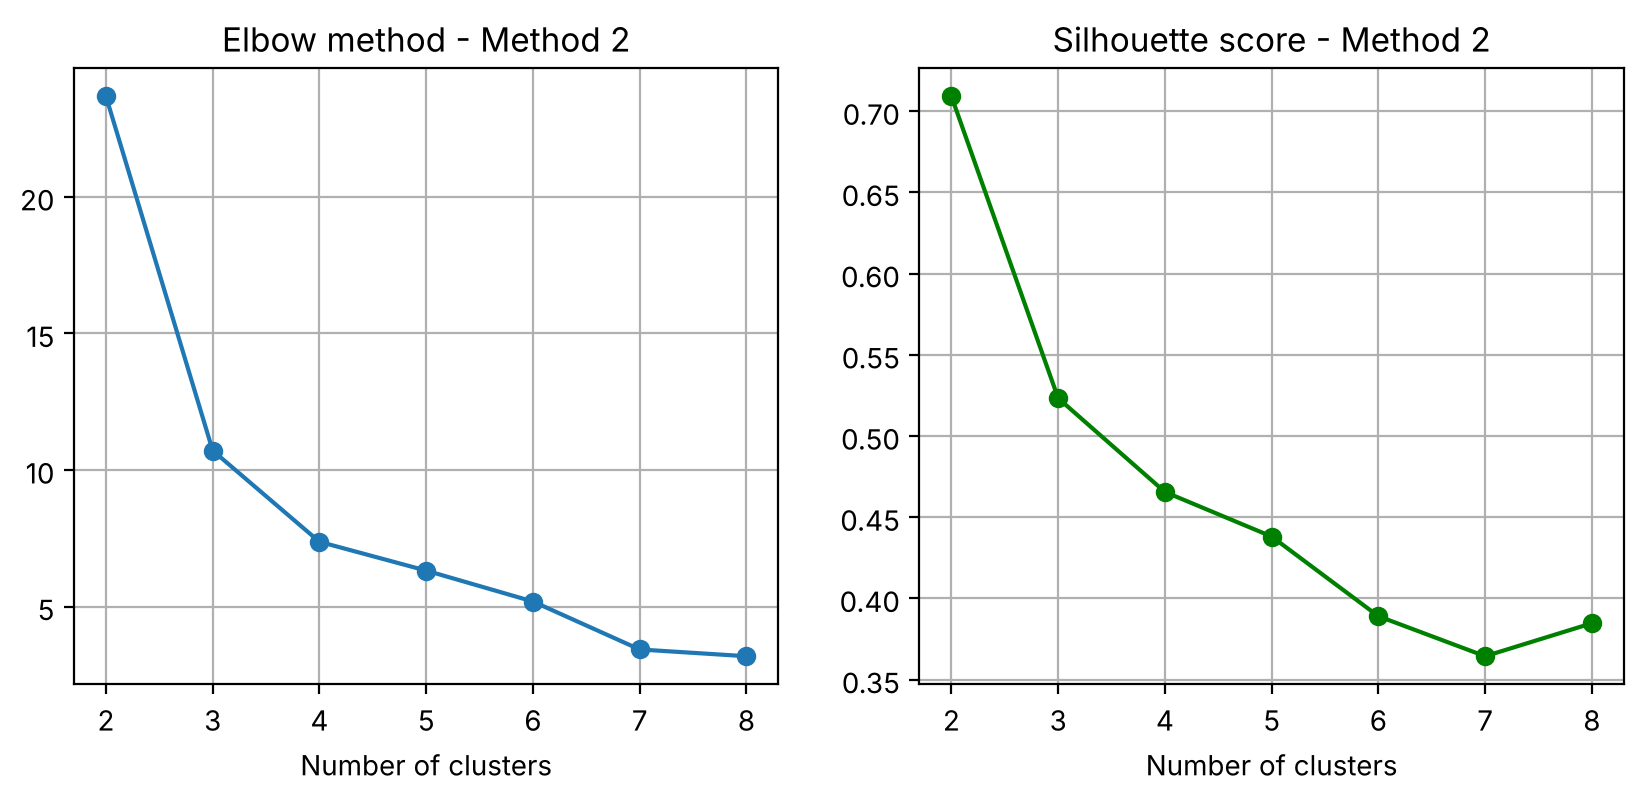

K = 2 - Inertia: 23.69 - Silhouette: 0.709
K = 3 - Inertia: 10.71 - Reduction vs. previous K: 12.97 - Silhouette: 0.523
K = 4 - Inertia: 7.37 - Reduction vs. previous K: 3.34 - Silhouette: 0.466
K = 5 - Inertia: 6.32 - Reduction vs. previous K: 1.05 - Silhouette: 0.438
K = 6 - Inertia: 5.18 - Reduction vs. previous K: 1.13 - Silhouette: 0.389
K = 7 - Inertia: 3.43 - Reduction vs. previous K: 1.76 - Silhouette: 0.364
K = 8 - Inertia: 3.18 - Reduction vs. previous K: 0.25 - Silhouette: 0.385


In [15]:
def dynamic_kmeans_multi(XDs,K):
  XC=XDs[0:K,:].copy()  #Seeds: the first K records (as in class)
  nc=np.zeros(len(XDs))
  for k in range(len(XDs)):
    d=np.sqrt(np.sum((XC-XDs[k,:])**2,axis=1))  #Euclidean distance to the centers
    cl=int(np.argmin(d))
    XC[cl,:]=(XC[cl,:]+XDs[k,:])/2               #Moves the center to the midpoint
  #Reassignment with the final centers
  for k in range(len(XDs)):
    d=np.sqrt(np.sum((XC-XDs[k,:])**2,axis=1))
    nc[k]=int(np.argmin(d))
  return XC,nc.astype(int)

Ks=range(2,9); W=[]; S=[]
for K in Ks:
  XCk,nck=dynamic_kmeans_multi(XDs,K)
  W.append(np.sum((XDs-XCk[nck])**2))
  S.append(silhouette_score(XDs,nck))

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(Ks,W,marker='o'); plt.title('Elbow method - Method 2'); plt.xlabel('Number of clusters'); plt.grid()
plt.subplot(1,2,2)
plt.plot(Ks,S,marker='o',color='green'); plt.title('Silhouette score - Method 2'); plt.xlabel('Number of clusters'); plt.grid()
plt.show()

for i in range(len(Ks)):
  if i==0:
    print("K =" ,Ks[i] ,"- Inertia:" ,round(W[i],2) ,"- Silhouette:" ,round(S[i],3))
  else:
    print("K =" ,Ks[i] ,"- Inertia:" ,round(W[i],2) ,"- Reduction vs. previous K:" ,round(W[i-1]-W[i],2) ,"- Silhouette:" ,round(S[i],3))

**Decision:** the largest drops in inertia happen from 2 to 3 clusters (12.97) and from 3 to 4 (3.34); after that the reductions are small (between 1.05 and 1.76). The silhouette falls from 0.709 with K = 2 to 0.438 with K = 5: the separation is moderate because daily frequency and severity overlap a lot.

**K = 5** is kept for two reasons: it's consistent with Method 1 and with the risk matrices, and it isolates in its own cluster the small group of days with catastrophic losses (see the profile table in step 5). With fewer clusters, those days would be mixed in with normal days.

## 4. Dynamic clustering cycle (dynamic k-means)

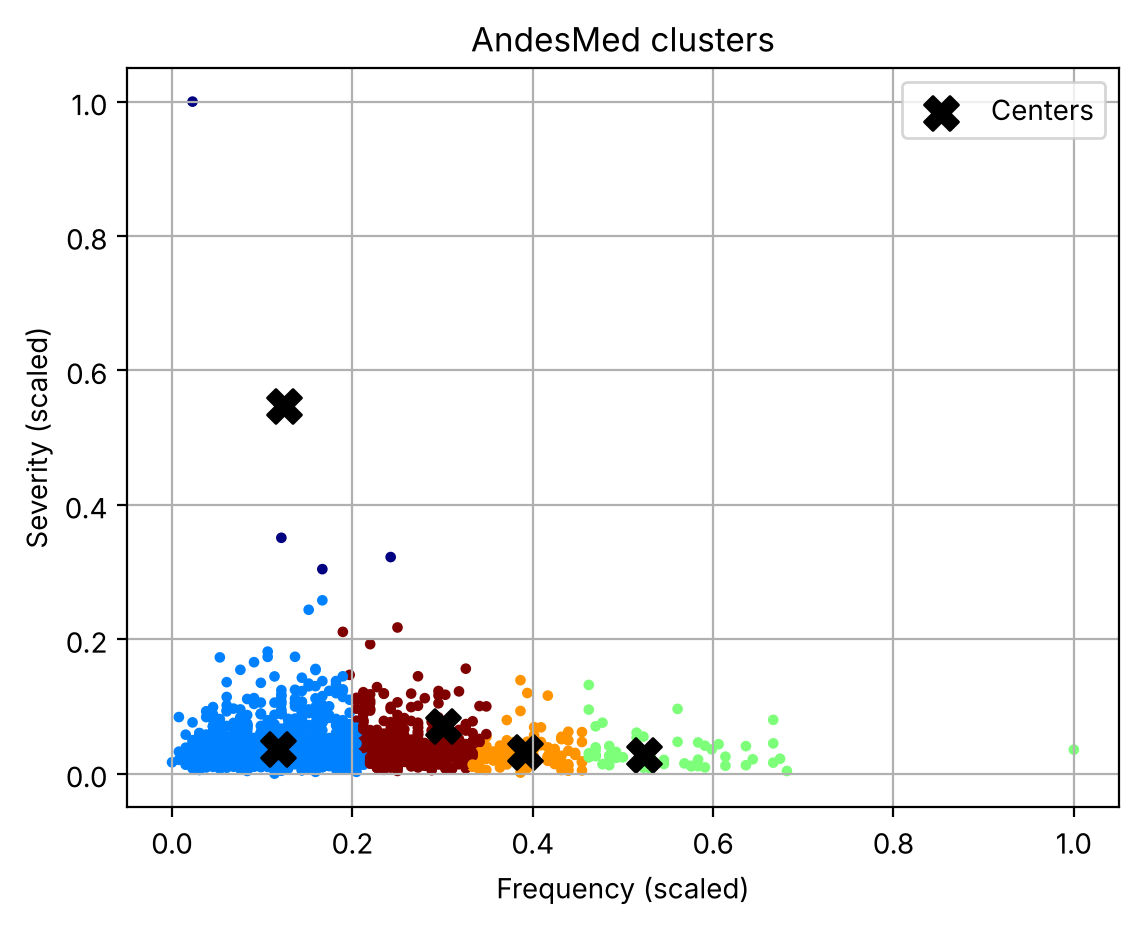

In [16]:
XCm,ncm=dynamic_kmeans_multi(XDs,5)

plt.figure()
plt.scatter(XDs[:,0],XDs[:,1],c=ncm,cmap='jet',s=8)
plt.scatter(XCm[:,0],XCm[:,1],c='black',marker='X',s=150,label='Centers')
plt.xlabel('Frequency (scaled)'); plt.ylabel('Severity (scaled)')
plt.title('AndesMed clusters')
plt.legend()
plt.grid()
plt.show()

## 5. Profile table by cluster

In [17]:
#Radius of each cluster: average distance from the internal data to its center
R=np.zeros(5)
for i in range(5):
  rows=np.where(ncm==i)[0]
  R[i]=np.mean(np.sqrt(np.sum((XDs[rows,:]-XCm[i,:])**2,axis=1)))

df=pd.DataFrame(scaler.inverse_transform(XCm),columns=XD.columns)  #Centers in real units
df['Internal records']=[np.sum(ncm==i) for i in range(5)]
df['Radius (scaled)']=R
display(df)

,Break_Frequency,Severity_COP,Internal records,Radius (scaled)
0,17.339079,2.219825e+07,4,0.290402
1,16.537702,1.821265e+06,903,0.053850
2,70.091539,1.482590e+06,55,0.069951
3,52.732056,1.668004e+06,127,0.036165
4,40.597991,3.204446e+06,411,0.062558


## 6. Integrating the Glacia records
Each Glacia record is assigned to its closest cluster and **integrated only if it's as close to the center as the internal data are, on average**.

,Frequency,Severity (MCOP),Distance to center,Assigned cluster,Decision
0,14,3.299876,0.041794,1,Integrated
1,7,7.018050,0.149103,-1,Rejected
2,29,2.279992,0.090875,-1,Rejected
3,13,8.377432,0.166711,-1,Rejected
4,22,4.834736,0.086211,-1,Rejected
5,21,9.493389,0.195496,-1,Rejected
6,6,12.591979,0.255940,0,Integrated
7,6,5.733098,0.126537,-1,Rejected
8,6,2.554433,0.081924,-1,Rejected
9,27,2.432003,0.080728,-1,Rejected


Decision
Rejected      1180
Integrated     320
Name: count, dtype: int64


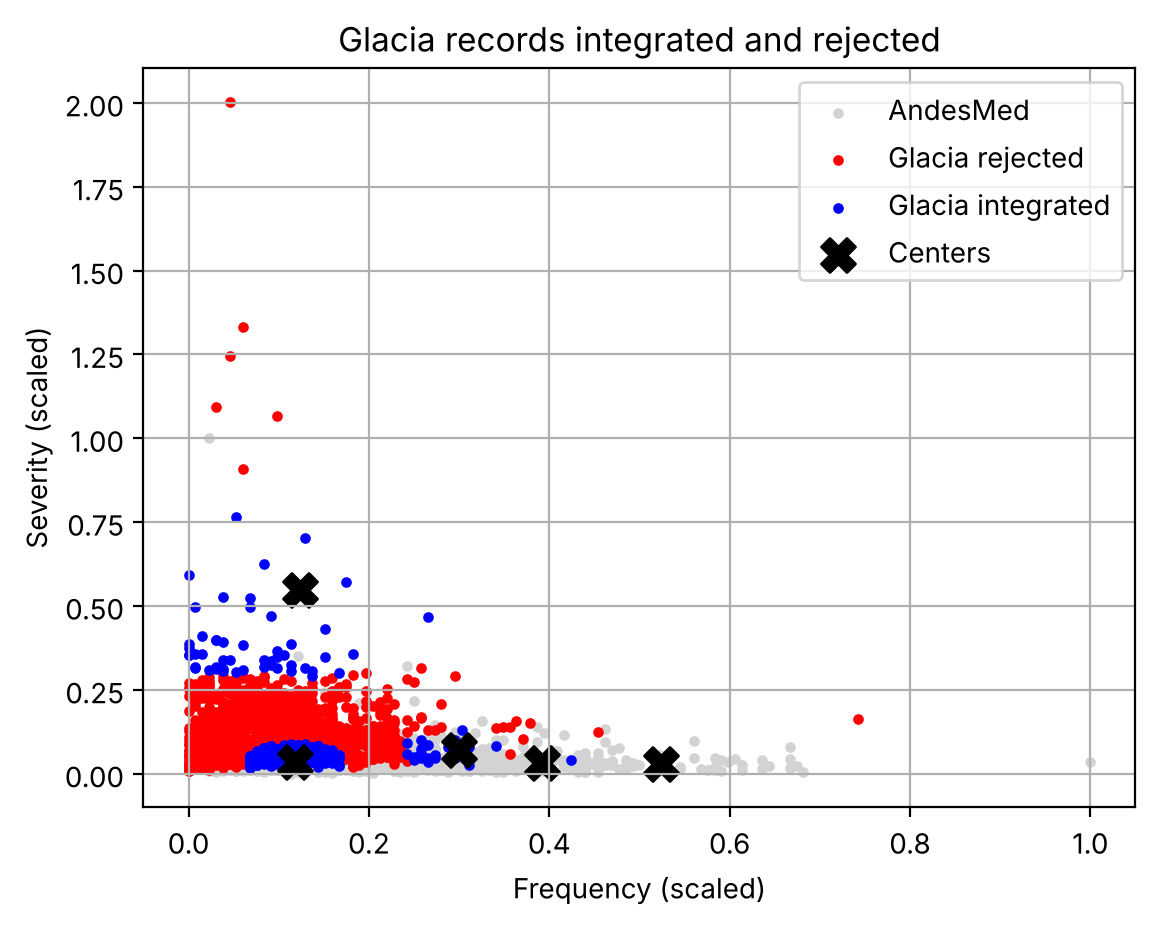

In [18]:
XCiu3=[]   #Cluster each Glacia record is integrated into
dmin=[]    #Distance to the closest center

for k in range(len(XDes)):
  d=np.sqrt(np.sum((XCm-XDes[k,:])**2,axis=1))
  nc=int(np.argmin(d))
  dmin.append(d[nc])
  if d[nc]<=R[nc]:
    XCiu3.append(nc)
  else:
    XCiu3.append(-1)
XCiu3=np.array(XCiu3)

#Transfer record in the Glacia dataset
dfe2=pd.DataFrame({'Frequency':XDE.iloc[:,5],'Severity (MCOP)':XDE.iloc[:,6]/1e6,'Distance to center':dmin,'Assigned cluster':XCiu3})
dfe2['Decision']=np.where(XCiu3>=0,'Integrated','Rejected')
display(dfe2.head(10))
print(dfe2['Decision'].value_counts())

plt.figure()
plt.scatter(XDs[:,0],XDs[:,1],c='lightgray',s=8,label='AndesMed')
plt.scatter(XDes[XCiu3<0,0],XDes[XCiu3<0,1],c='red',s=8,label='Glacia rejected')
plt.scatter(XDes[XCiu3>=0,0],XDes[XCiu3>=0,1],c='blue',s=8,label='Glacia integrated')
plt.scatter(XCm[:,0],XCm[:,1],c='black',marker='X',s=150,label='Centers')
plt.xlabel('Frequency (scaled)'); plt.ylabel('Severity (scaled)')
plt.title('Glacia records integrated and rejected')
plt.legend()
plt.grid()
plt.show()

## 7. Sampling 1,000 records

,AndesMed in the cluster,Glacia integrated,AndesMed sample,Glacia sample,Total sample
0,4,51,0,2,2
1,903,246,469,135,604
2,55,0,36,0,36
3,127,1,83,1,84
4,411,22,263,11,274


Records in the integrated dataset (Method 2): 1000
Source
AndesMed    851
Glacia      149
Name: count, dtype: int64


,ID,Date,Vehicle_Type,Route,Main_Cause,Break_Frequency,Severity_COP,LDA,Shipments,Source
0,1113,2025-01-17,Refrigerated truck,Medellín-Bucaramanga,Route delay,1,15288333,15288333,1544,Glacia
1,42,2022-02-11,Refrigerated truck,Medellín-Bogotá,Refrigeration failure,15,14523831,217857465,1481,Glacia
2,74,2022-03-15,Refrigerated van,Medellín-Bogotá,Operational error,25,1433617,35840425,642,AndesMed
3,906,2024-06-24,Refrigerated truck,Medellín-Cali,Sensor failure,15,2314639,34719585,666,AndesMed
4,800,2024-03-10,Refrigerated truck,Medellín-Bucaramanga,Electrical failure,14,2540161,35562254,233,AndesMed


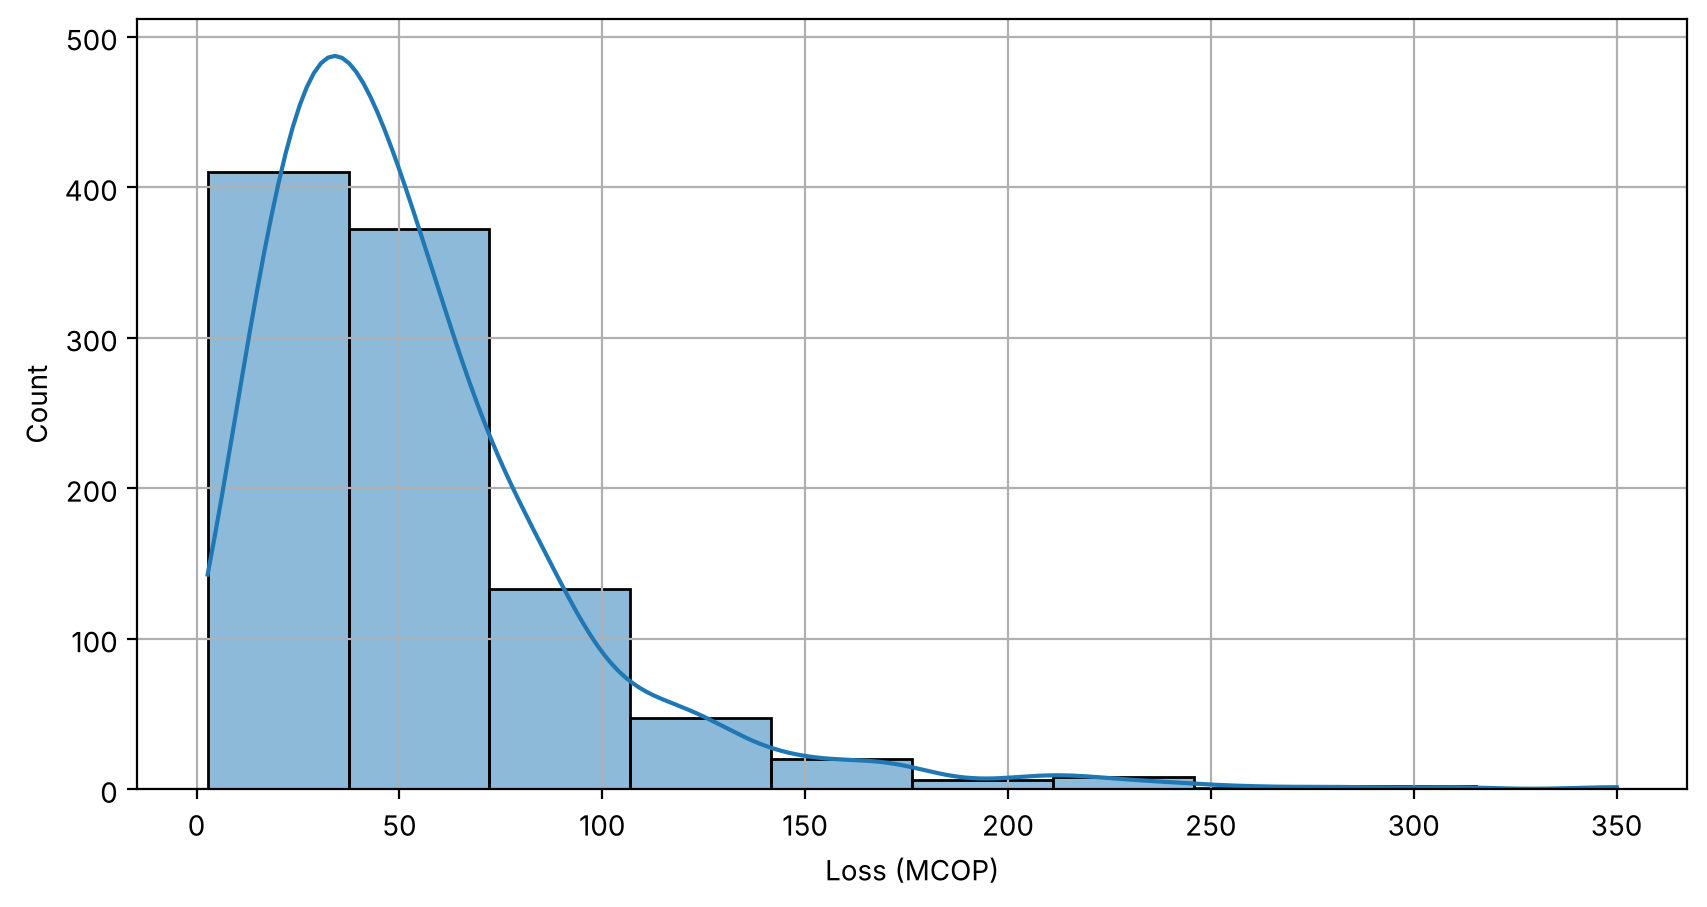

Distribution integrated with Method 2 - mean: 53.76233968910001 - skewness: 2.1444111552238176 - kurtosis: 7.185677769458392
The mean discrepancy is (%): 2.1914989248559333


In [19]:
pm2=(np.array([np.sum(ncm==i) for i in range(5)])/len(ncm)*1000).astype(int)
pm2[np.argmax(pm2)]=pm2[np.argmax(pm2)]+(1000-np.sum(pm2))

random.seed(42)
rows2=[]; sample2=[]
for i in range(5):
  box=list(np.where(ncm==i)[0])+list(len(XDB)+np.where(XCiu3==i)[0])  #Internal + external records in the cluster
  sample2.append(random.sample(box,k=pm2[i]))
  rows2.extend(sample2[i])

mint=[];mext=[]
for i in range(5):
  m=np.array(sample2[i])
  mint.append(np.sum(m<len(XDB))); mext.append(np.sum(m>=len(XDB)))
TB2=pd.DataFrame({'AndesMed in the cluster':[np.sum(ncm==i) for i in range(5)],'Glacia integrated':[np.sum(XCiu3==i) for i in range(5)],
                  'AndesMed sample':mint,'Glacia sample':mext,'Total sample':pm2})
display(TB2)

XDB2=XT.iloc[rows2,:].reset_index(drop=True)  #Integrated dataset - Method 2
LDA2m=np.array(XDB2.iloc[:,5]*XDB2.iloc[:,6]/1e6)

print("Records in the integrated dataset (Method 2):" ,len(XDB2))
print(XDB2['Source'].value_counts())
display(XDB2.head())

u4,s4,c4,k4,df4=characterize(LDA2m)
print("Distribution integrated with Method 2 - mean:" ,u4 ,"- skewness:" ,c4 ,"- kurtosis:" ,k4)
print("The mean discrepancy is (%):" ,np.abs((u1-u4)/u1)*100)

**Results – Method 2**

Method 2 integrated 320 of the 1,500 Glacia records and rejected 1,180. Because it looks at frequency and severity at the same time, it only accepts Glacia days that resemble some AndesMed profile. Most rejected records are days with few breaks and high severity, which are typical of Glacia.

The integrated dataset preserves the original distribution very well: the mean is 53.76 million COP (2.2% discrepancy), and skewness (2.14) and kurtosis (7.2) stay close to the original.

# 2. Credibility theory

## 2.1 Error of the internal data

In [20]:
z=2     #Number of standard deviations considered for reliability
p=0.95  #Share of the data within two standard deviations

ND=len(LDA)
u=np.mean(LDA); sigma=np.std(LDA)
print("Lower limit of 95% of the data (MCOP):" ,u-2*sigma)
print("Upper limit of 95% of the data (MCOP):" ,u+2*sigma)

E=z*np.sqrt((p*(1-p))/ND)
print("The error in the estimate from my data is (%):" ,E*100)

#The error is applied as a percentage of the mean
print("Mean minus the error (MCOP):" ,u*(1-E))
print("Mean plus the error (MCOP):" ,u*(1+E))
print("The gap is (MCOP):" ,u*(1+E)-u*(1-E))

#And with the integrated dataset of 1000 records?
E1000=z*np.sqrt((p*(1-p))/1000)
print("The error with 1000 records is (%):" ,E1000*100)

Lower limit of 95% of the data (MCOP): -35.79986381114875
Upper limit of 95% of the data (MCOP): 145.18533371114873
The error in the estimate from my data is (%): 1.125462867742276
Mean minus the error (MCOP): 54.077188526785044
Mean plus the error (MCOP): 55.30828137321494
The gap is (MCOP): 1.2310928464298954
The error with 1000 records is (%): 1.3784048752090228


## 2.2 Credibility theory
How much should I trust the external data? Does the external data resemble mine?

In [21]:
def credibility(LDA,LDAe):
  ND=len(LDA); NDe=len(LDAe)
  uo=np.mean(LDA); ue=np.mean(LDAe)
  sigmao=np.std(LDA); sigmae=np.std(LDAe)

  EPV=(ND*sigmao**2+NDe*sigmae**2)/(ND+NDe)
  print("The weighted variance (EPV) is:" ,EPV)
  uh=(ND*uo+NDe*ue)/(ND+NDe)
  print("The weighted mean of the data is:" ,uh)
  VHM=((ND/(ND+NDe))*uo**2+(NDe/(ND+NDe))*ue**2)-uh**2
  print("The variance of the hypothetical means (VHM) is:" ,VHM)
  Cr=ND/(ND+(EPV/VHM))
  print("The credibility of my data is (%):" ,Cr*100)
  print("The credibility of the external data is (%):" ,(1-Cr)*100)
  return Cr

print("=== AndesMed vs. full Glacia ===")
Cr0=credibility(LDA,LDAe)

=== AndesMed vs. full Glacia ===
The weighted variance (EPV) is: 3469.418781972923
The weighted mean of the data is: 63.42975905466667
The variance of the hypothetical means (VHM) is: 76.33559020552639
The credibility of my data is (%): 97.05913679959797
The credibility of the external data is (%): 2.940863200402033


With 1,500 days of history, AndesMed's data has 97.06% credibility, versus 2.94% for Glacia's data. This happens because the variation of the loss within each company (EPV = 3,469.4) is 45 times larger than the difference between the two companies (VHM = 76.34), and the amount of internal data is far larger than that factor.

This means AndesMed can estimate its loss with its own data: the credibility-adjusted loss is 55.21 million COP per day, almost the same as its own mean of 54.69 million.

## 2.3 Credibility of the Glacia data left in each integrated dataset, and choice of dataset

Method 1
The weighted variance (EPV) is: 1765.4733368265622
The weighted mean of the data is: 51.04168813641246
The variance of the hypothetical means (VHM) is: 55.23539848760083
The credibility of my data is (%): 97.91361008045968
The credibility of the external data is (%): 2.0863899195403213
Mean discrepancy (%): 15.873324813499723
Mean frequency: 20.454 - Original: 27.482
Mean severity (MCOP): 2.8038193739999997 - Original: 2.079173562
Method 2
The weighted variance (EPV) is: 1930.9958060388067
The weighted mean of the data is: 53.916363182534866
The variance of the hypothetical means (VHM) is: 6.067984442788202
The credibility of my data is (%): 82.49795500486636
The credibility of the external data is (%): 17.502044995133648
Mean discrepancy (%): 1.536550746215699
Mean frequency: 27.188 - Original: 27.482
Mean severity (MCOP): 2.08728481 - Original: 2.079173562


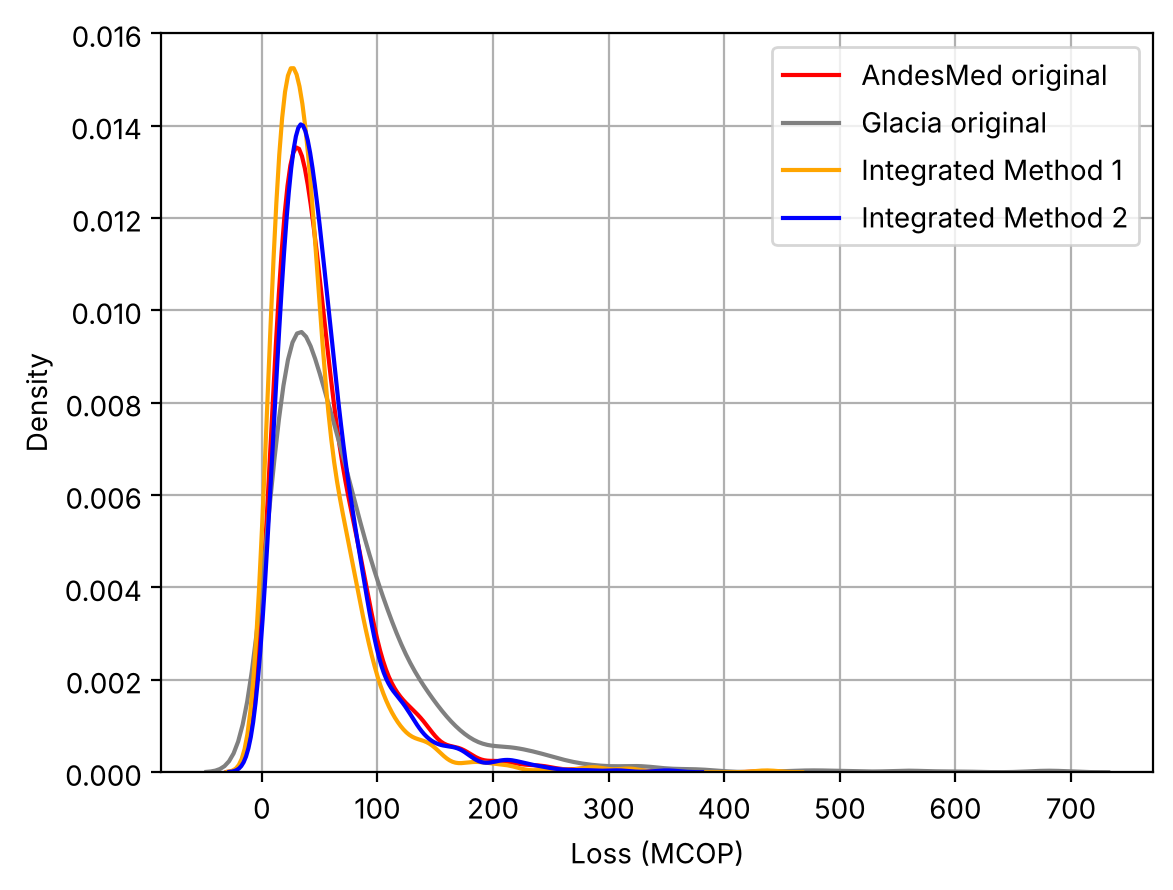

In [22]:
for name,base,L in [('Method 1',XDB1,LDA2e),('Method 2',XDB2,LDA2m)]:
  print("======================")
  print(name)
  rowsGlacia=np.where(base['Source']=='Glacia')[0]
  Cr=credibility(LDA,L[rowsGlacia])
  print("Mean discrepancy (%):" ,np.abs((np.mean(LDA)-np.mean(L))/np.mean(LDA))*100)
  print("Mean frequency:" ,np.mean(base.iloc[:,5]) ,"- Original:" ,np.mean(Freq))
  print("Mean severity (MCOP):" ,np.mean(base.iloc[:,6])/1e6 ,"- Original:" ,np.mean(Sev))

plt.figure()
sns.kdeplot(LDA,color='red',label='AndesMed original')
sns.kdeplot(LDAe,color='gray',label='Glacia original')
sns.kdeplot(LDA2e,color='orange',label='Integrated Method 1')
sns.kdeplot(LDA2m,color='blue',label='Integrated Method 2')
plt.xlabel('Loss (MCOP)')
plt.legend()
plt.grid()
plt.show()

**Selection criterion:** the **Method 2** dataset is chosen. Its mean discrepancy is 1.5%, versus 15.9% for Method 1 (computed with the direct mean of the losses; sections 1.6.3 and 7 show 2.2% and 15.8% because there the mean is estimated from the histogram's class marks). It also keeps AndesMed's frequency (27.2 vs. 27.5 breaks per day) and severity (2.09 vs. 2.08 million COP) almost unchanged. The Method 1 dataset, on the other hand, lowers the frequency to 20.5 and raises the severity to 2.80 million, which would distort the risk matrices.

The Glacia records integrated by Method 2 have 17.5% credibility, versus 2.1% for those integrated by Method 1 and 2.9% for the full Glacia dataset. In other words, Method 2 selected the external data that most resembles AndesMed's.

In [23]:
XDBi=XDB2.copy()  #Selected integrated dataset
print("Records in the integrated dataset:" ,len(XDBi))
print(XDBi['Source'].value_counts())
display(XDBi.head(10))

XDBi.to_csv(data_path('DF_Integrated_AndesMed_Glacia_1000.csv'),index=False)

Records in the integrated dataset: 1000
Source
AndesMed    851
Glacia      149
Name: count, dtype: int64


,ID,Date,Vehicle_Type,Route,Main_Cause,Break_Frequency,Severity_COP,LDA,Shipments,Source
0,1113,2025-01-17,Refrigerated truck,Medellín-Bucaramanga,Route delay,1,15288333,15288333,1544,Glacia
1,42,2022-02-11,Refrigerated truck,Medellín-Bogotá,Refrigeration failure,15,14523831,217857465,1481,Glacia
2,74,2022-03-15,Refrigerated van,Medellín-Bogotá,Operational error,25,1433617,35840425,642,AndesMed
3,906,2024-06-24,Refrigerated truck,Medellín-Cali,Sensor failure,15,2314639,34719585,666,AndesMed
4,800,2024-03-10,Refrigerated truck,Medellín-Bucaramanga,Electrical failure,14,2540161,35562254,233,AndesMed
5,710,2023-12-11,Refrigerated truck,Medellín-Cali,Route delay,22,2231381,49090382,720,AndesMed
6,415,2023-02-19,Small refrigerated van,Cali-Pereira,Route delay,19,1223259,23241921,244,AndesMed
7,299,2022-10-26,Small refrigerated van,Cali-Pereira,Operational error,27,709024,19143648,715,AndesMed
8,1343,2025-09-04,Refrigerated truck,Bogotá-Barranquilla,Doors left open too long,11,2802656,30829216,1620,Glacia
9,249,2022-09-06,Refrigerated truck,Medellín-Bogotá,Refrigeration failure,25,5318552,132963800,687,AndesMed


# 3. Fuzzy logic – risk matrices with the integrated dataset
## 3.1 Number of frequency and severity clusters

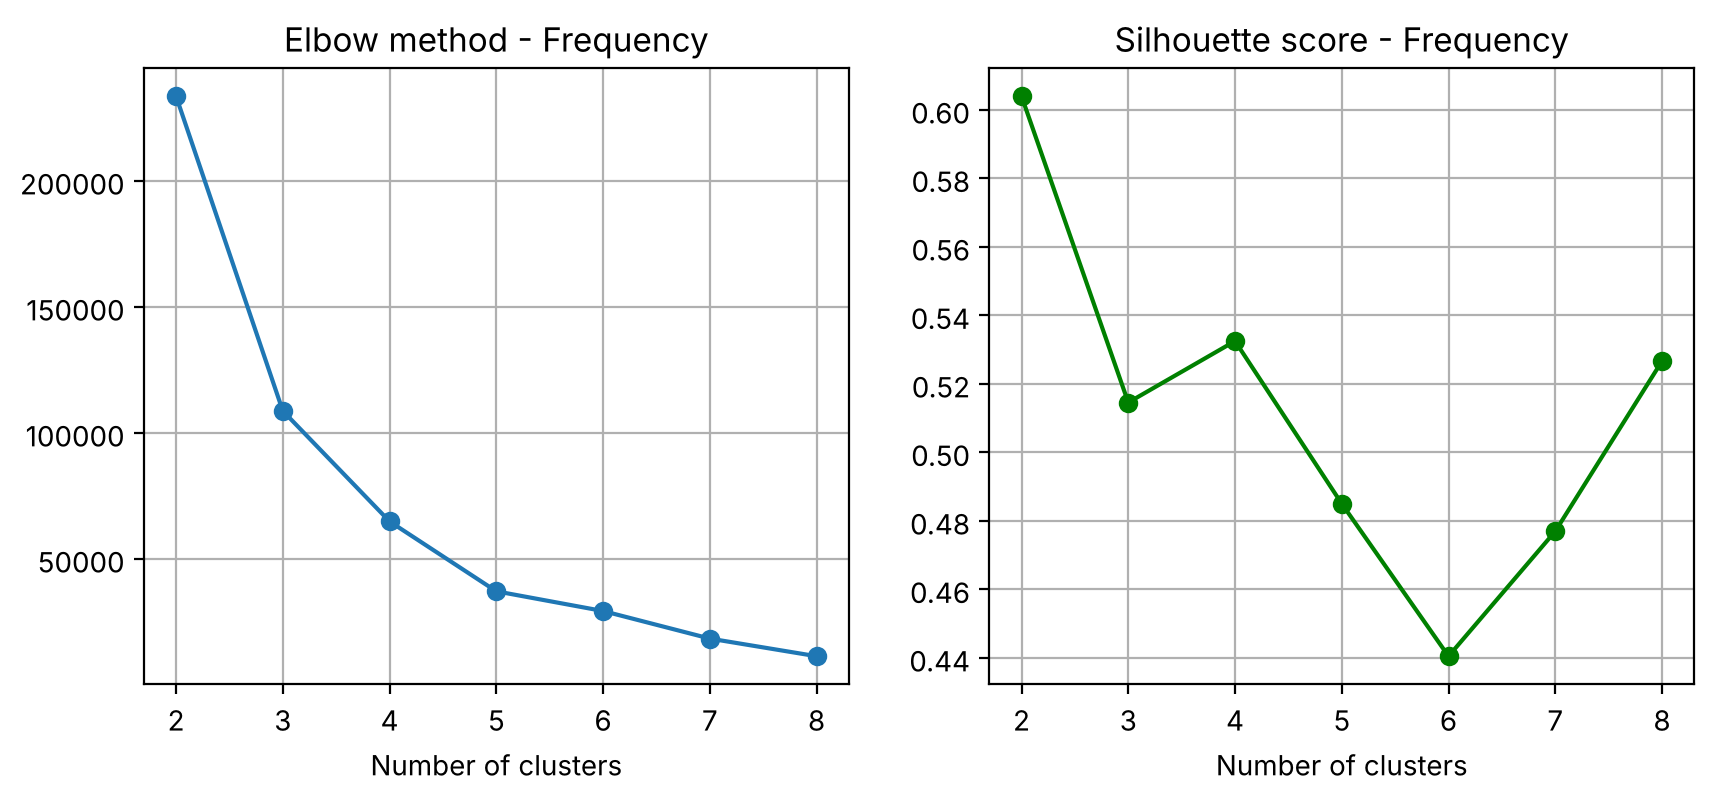

K = 2 - Inertia: 233628.8 - Silhouette: 0.604
K = 3 - Inertia: 108725.7 - Reduction vs. previous K: 124903.1 - Silhouette: 0.515
K = 4 - Inertia: 64867.6 - Reduction vs. previous K: 43858.1 - Silhouette: 0.533
K = 5 - Inertia: 37130.7 - Reduction vs. previous K: 27736.9 - Silhouette: 0.485
K = 6 - Inertia: 29306.2 - Reduction vs. previous K: 7824.5 - Silhouette: 0.44
K = 7 - Inertia: 18367.4 - Reduction vs. previous K: 10938.9 - Silhouette: 0.477
K = 8 - Inertia: 11364.0 - Reduction vs. previous K: 7003.4 - Silhouette: 0.527


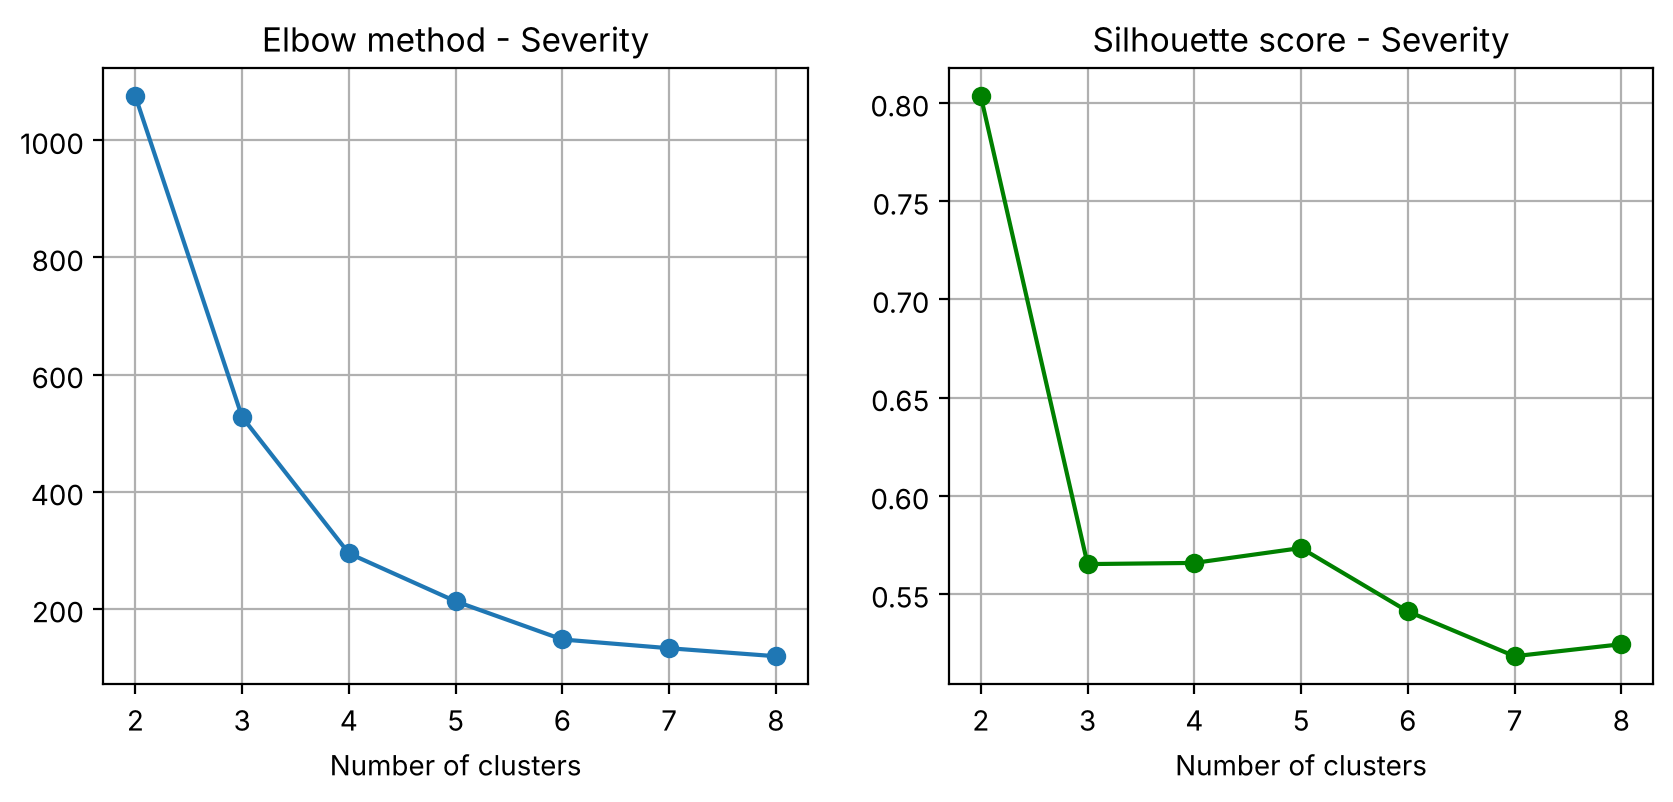

K = 2 - Inertia: 1075.5 - Silhouette: 0.803
K = 3 - Inertia: 527.5 - Reduction vs. previous K: 547.9 - Silhouette: 0.565
K = 4 - Inertia: 294.6 - Reduction vs. previous K: 232.9 - Silhouette: 0.566
K = 5 - Inertia: 212.7 - Reduction vs. previous K: 81.9 - Silhouette: 0.573
K = 6 - Inertia: 147.5 - Reduction vs. previous K: 65.2 - Silhouette: 0.541
K = 7 - Inertia: 132.6 - Reduction vs. previous K: 14.9 - Silhouette: 0.518
K = 8 - Inertia: 118.9 - Reduction vs. previous K: 13.7 - Silhouette: 0.524


In [24]:
Xf=np.array(XDBi.iloc[:,5]).astype(float)  #Break frequency
Xs=np.array(XDBi.iloc[:,6])/1e6            #Severity (MCOP)

Wf,Sf=elbow_silhouette(Xf,'Frequency')
Ws,Ss=elbow_silhouette(Xs,'Severity')

**Number of clusters:** for frequency, inertia drops by 27,737 from 4 to 5 clusters and only by 7,825 from 5 to 6, so the elbow is at 5 (silhouette of 0.485). For severity, the silhouette with 5 clusters (0.573) is the highest after K = 2, and inertia keeps dropping substantially up to 5. **5 clusters** are used for each variable, which also match the 5 levels of the matrices.

## 3.2 Frequency and severity fuzzy sets

In [25]:
np.random.seed(42)
XCf,ncf=clustering(Xf)
lbf=['Rare','Unlikely','Moderate','Likely','Certain']
XCs,ncs=clustering(Xs)
lbs=['Insignificant','Minor','Significant','Major','Severe']

sigmaf=[]; sigmas=[]
for i in range(5):
  sigmaf.append(np.sqrt((np.sum((XCf-XCf[i,])**2)/4)))
  sigmas.append(np.sqrt((np.sum((XCs-XCs[i,])**2)/4)))

print("The frequency clusters are:" ,XCf)
print("The severity clusters (MCOP) are:" ,XCs)

The frequency clusters are: [ 6.52939905 13.82492816 32.36346043 39.76667565 79.91607165]
The severity clusters (MCOP) are: [1.50698163 2.21493807 3.37978137 5.13020239 8.92583422]


## 3.3 Membership matrix

Reference frequency: 27.188
Reference severity (MCOP): 2.0872848100000003


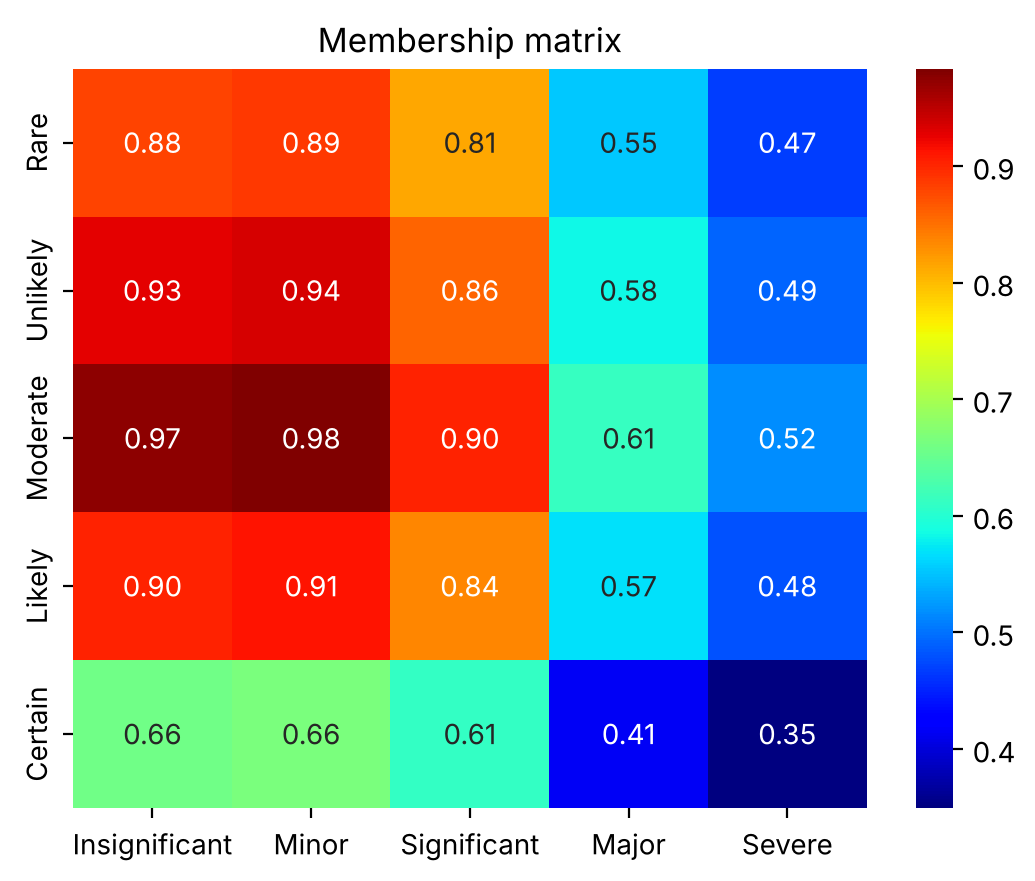

In [26]:
Xfp=np.mean(Xf); Xsp=np.mean(Xs)
print("Reference frequency:" ,Xfp)
print("Reference severity (MCOP):" ,Xsp)

VPf=np.exp(-0.5*((XCf-Xfp)/sigmaf)**2)
VPs=np.exp(-0.5*((XCs-Xsp)/sigmas)**2)
MVP=np.outer(VPf,VPs)

plt.figure()
sns.heatmap(MVP,annot=True,fmt='.2f',cmap='jet',xticklabels=lbs,yticklabels=lbf)
plt.title('Membership matrix')
plt.show()

The matrix shows which scenarios a typical day of operation resembles. It mostly resembles days of Moderate frequency with Insignificant or Minor severity (0.97 and 0.98). Even so, it keeps a resemblance of 0.35 to 0.52 with the Severe-severity scenarios.

This means a normal AndesMed day has a moderate number of breaks, and almost all of them are cheap. But even a normal day can end up being expensive, so the company can't manage its risk with averages alone. That's why the estimated loss rises from 56.7 million (traditional calculation) to 115.6 million COP when this uncertainty is taken into account (LDAm) in the loss matrix.

## 3.4 Loss matrix

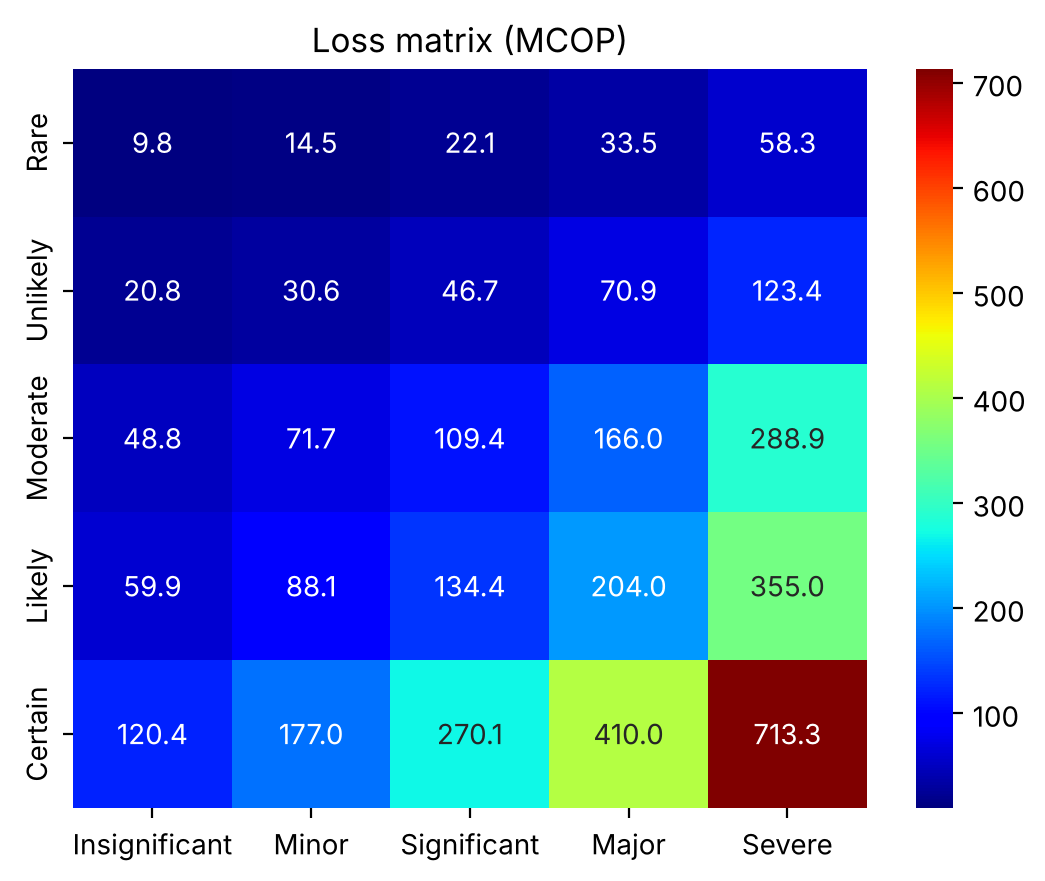

The traditional loss is (MCOP): 56.74909941428
The loss with the membership matrix is (MCOP): 115.62850238392548


In [27]:
MP=np.outer(XCf,XCs)

plt.figure()
sns.heatmap(MP,annot=True,fmt='.1f',cmap='jet',xticklabels=lbs,yticklabels=lbf)
plt.title('Loss matrix (MCOP)')
plt.show()

LDAr=Xfp*Xsp
print('The traditional loss is (MCOP):' ,LDAr)
LDAm=np.sum(MVP*MP)/np.sum(MVP)
print('The loss with the membership matrix is (MCOP):' ,LDAm)

It shows the daily loss of each scenario. The best case (Rare–Insignificant) costs 9.8 million COP and the worst (Certain–Severe), 713.3 million: about 73 times more.

In this particular case, frequency weighs more than severity:

* Moving down (from Rare to Certain) multiplies the loss by about 12. In the Severe column, it goes from 58.3 to 713.3.
* Moving right (from Insignificant to Severe) multiplies it by about 6. In the Certain row, it goes from 120.4 to 713.3.

For AndesMed, what makes a day most expensive is how many breaks occur, more than how much each one costs. This matches its profile as a company with many relatively cheap breaks.

## 3.5 Event matrix

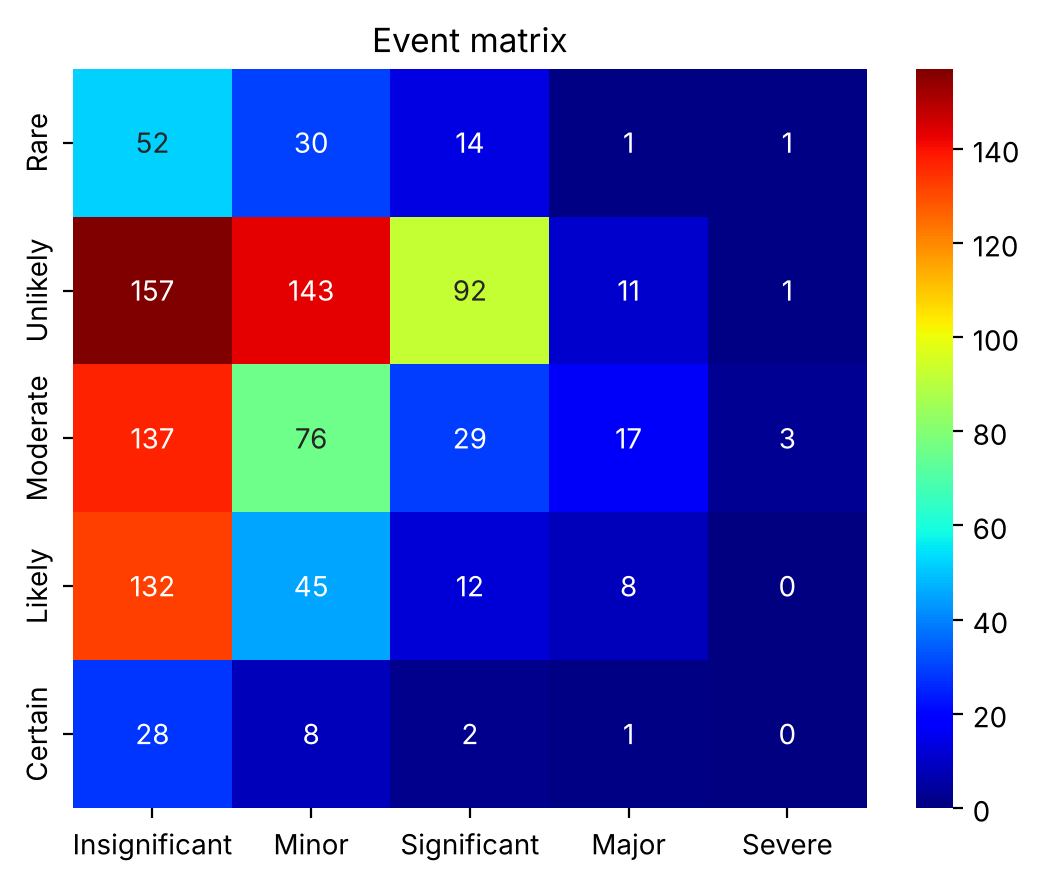

The loss with the event matrix is (MCOP): 51.37939049048788
Records with Insignificant severity: 50.6 %
Records with Minor severity: 30.2 %
Records with Significant severity: 14.899999999999999 %
Records with Major severity: 3.8 %
Records with Severe severity: 0.5 %


In [28]:
ME=np.zeros((5,5))
for k in range(len(XDBi)):
  row=int(ncf[k,0])
  column=int(ncs[k,0])
  ME[row,column]=ME[row,column]+1

plt.figure()
sns.heatmap(ME,annot=True,fmt='.0f',cmap='jet',xticklabels=lbs,yticklabels=lbf)
plt.title('Event matrix')
plt.show()

LDAm2=np.sum(MP*MVP*ME)/np.sum(MVP*ME)
print('The loss with the event matrix is (MCOP):' ,LDAm2)

for i in range(5):
  print(f'Records with {lbs[i]} severity:' ,np.sum(ME[:,i])/np.sum(ME)*100 ,'%')

This matrix counts which scenario each of the 1,000 days fell into.

* By severity: 50.6% of days had breaks of insignificant cost, 30.2% minor, 14.9% significant, 3.8% major and only 0.5% (5 days) severe.
* By frequency: most days have Unlikely (404 days) or Moderate (262) frequency. Only 39 days had the highest frequency.
* The fullest cells are Unlikely–Insignificant (157 days) and Unlikely–Minor (143).
* Days with many breaks are almost never serious. Of the 39 days with Certain frequency, 28 had insignificant cost. And the 5 severe days happened with low or moderate frequency.

## Implications

1. The operation is stable most of the time. 80.8% of days only have breaks of insignificant or minor cost.
2. There are two kinds of problem days. Some have many cheap breaks, linked to everyday operational failures. Others have few breaks, but very expensive ones, such as a refrigeration failure that ruins a whole load. Each kind needs different management: the first is reduced with processes and training, and the second with maintenance of the cooling equipment, real-time temperature monitoring and contingency plans.
3. It adjusts the model to reality. Because severe scenarios almost never happen, the estimated loss falls from 115.6 to 51.4 million COP per day when this matrix is included.

### 3.5.1 Which causes, vehicles, routes and sources appear at each severity level?

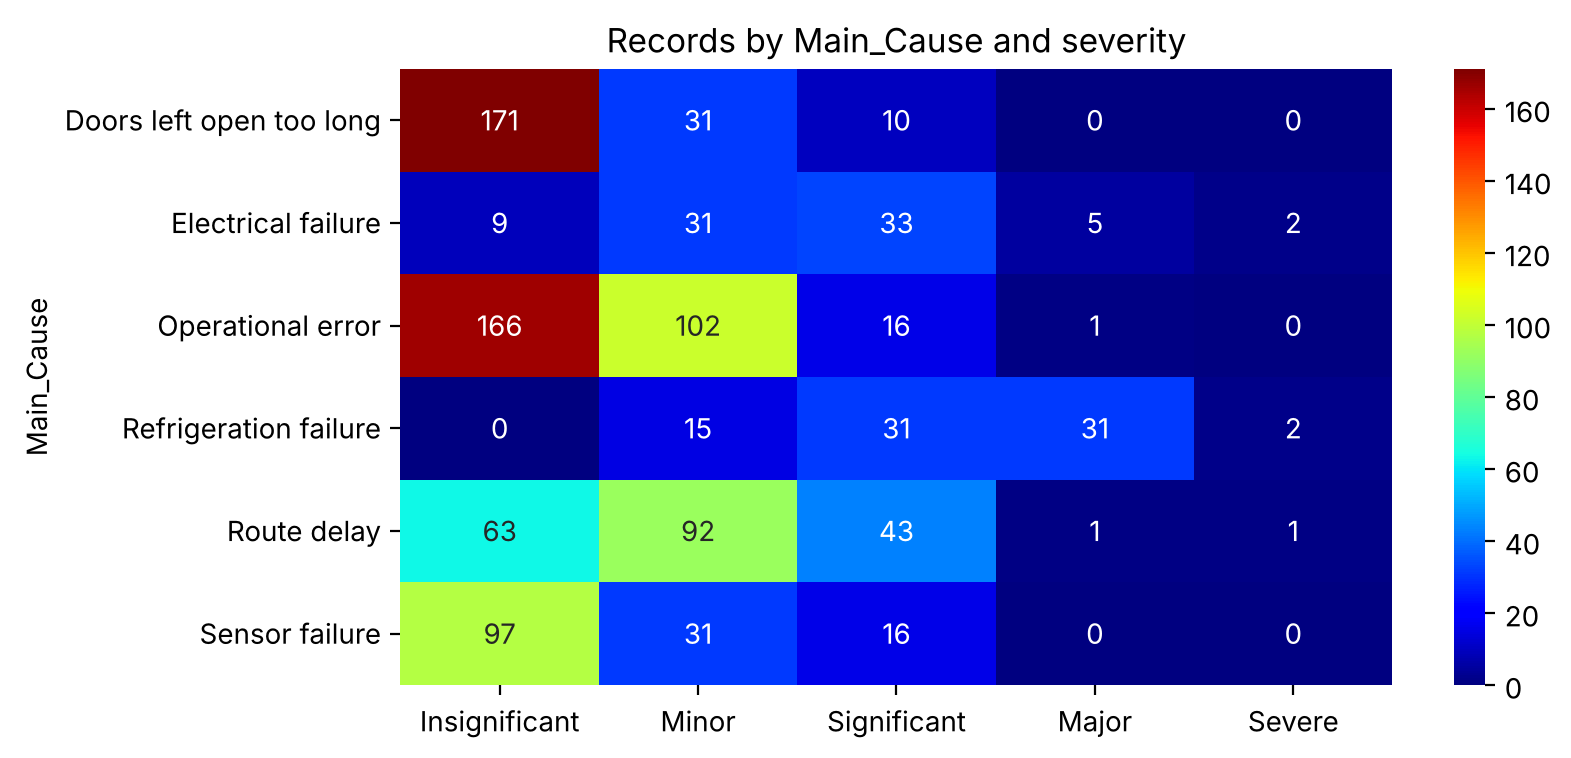

Percentage of the total loss by Main_Cause:
 Main_Cause
Doors left open too long    12.508768
Electrical failure          12.085894
Operational error           26.164107
Refrigeration failure       16.856734
Route delay                 21.800759
Sensor failure              10.583739
Name: Loss, dtype: float64


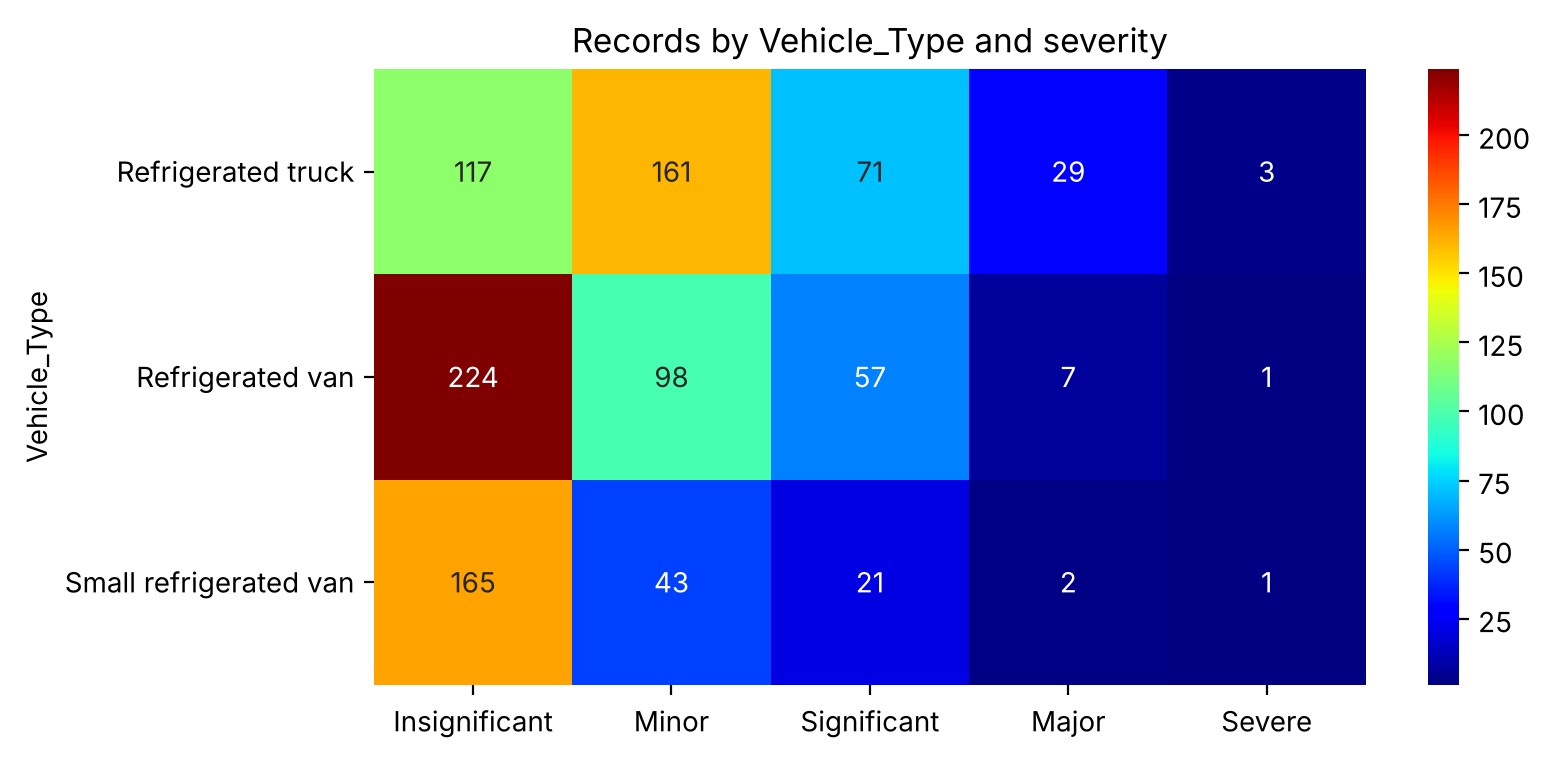

Percentage of the total loss by Vehicle_Type:
 Vehicle_Type
Refrigerated truck        40.639288
Refrigerated van          38.217121
Small refrigerated van    21.143591
Name: Loss, dtype: float64


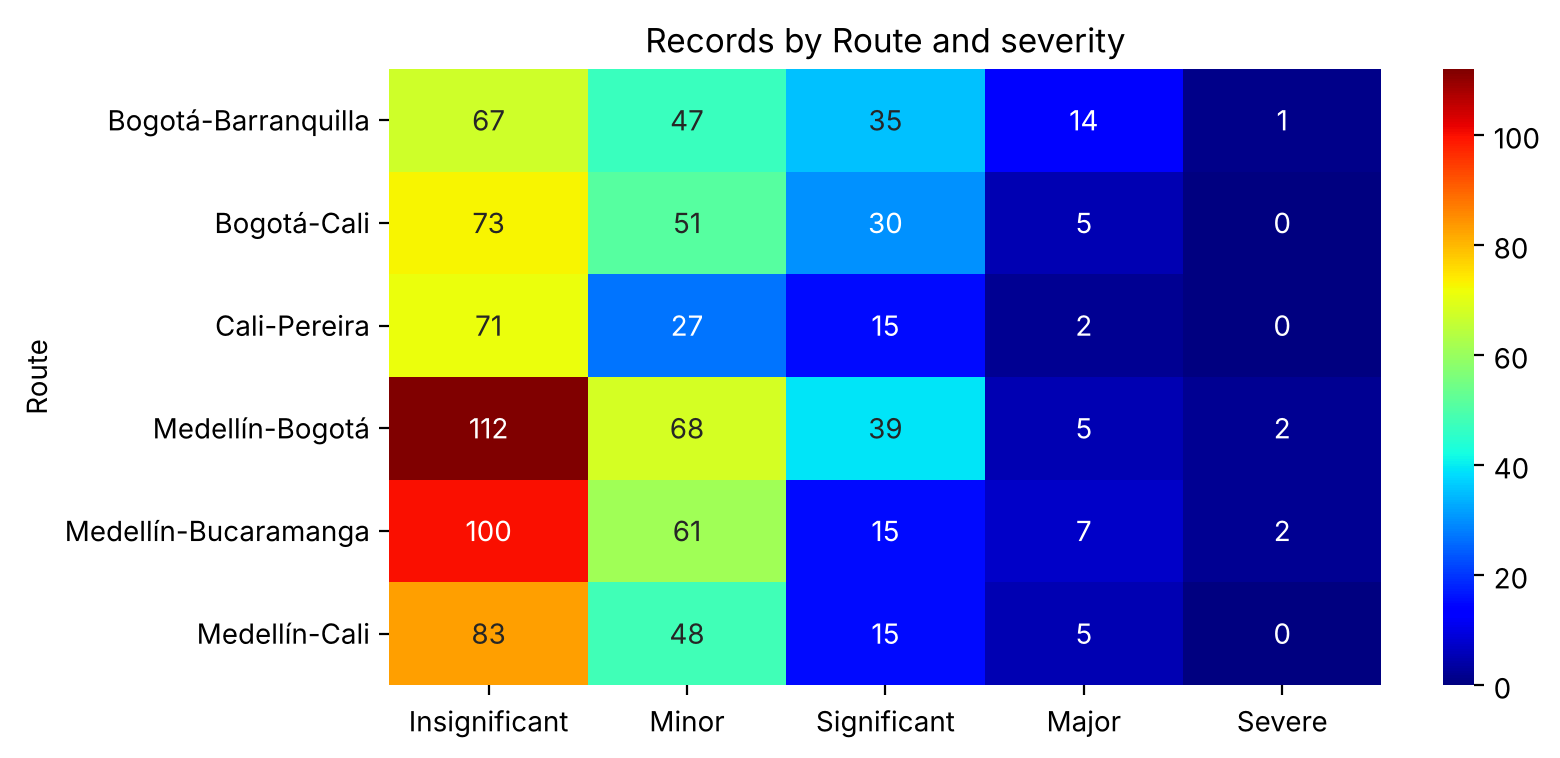

Percentage of the total loss by Route:
 Route
Bogotá-Barranquilla     21.988772
Bogotá-Cali             16.211768
Cali-Pereira             8.167751
Medellín-Bogotá         21.795817
Medellín-Bucaramanga    18.493852
Medellín-Cali           13.342040
Name: Loss, dtype: float64


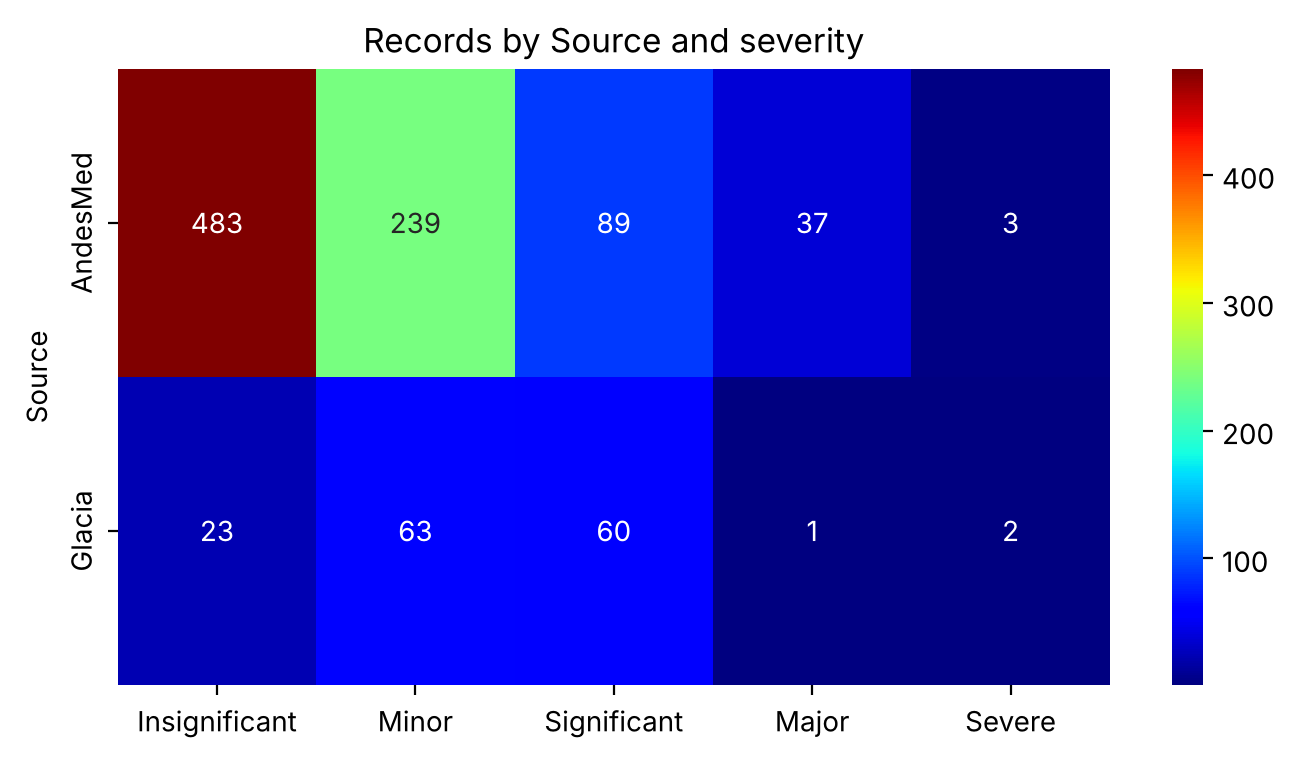

Percentage of the total loss by Source:
 Source
AndesMed    87.244791
Glacia      12.755209
Name: Loss, dtype: float64


In [29]:
XDBi['Severity cluster']=ncs[:,0]
XDBi['Loss']=Xf*Xs

for col in ['Main_Cause','Vehicle_Type','Route','Source']:
  MR=pd.DataFrame()
  for i in range(5):
    MR[lbs[i]]=XDBi.groupby(col)['Severity cluster'].apply(lambda x: np.sum(x==i))

  plt.figure(figsize=(8,4))
  sns.heatmap(MR,annot=True,fmt='.0f',cmap='jet')
  plt.title(f'Records by {col} and severity')
  plt.show()

  PR=XDBi.groupby(col)['Loss'].apply(lambda x: np.sum(x)/np.sum(XDBi['Loss'])*100)
  print(f"Percentage of the total loss by {col}:\n" ,PR)

## Main findings
* Operational errors and route delays generate almost half of the loss (48%). They're frequent, but almost always cheap.

* Refrigeration failures are never mild. They appear on few days, but 64 of their 79 days have significant or major severity. Together with electrical failures, they explain 4 of the 5 severe days.

* Refrigerated trucks and the Bogotá–Barranquilla route concentrate the serious days. Trucks account for 29 of the 38 days of major severity. Bogotá–Barranquilla has 30% of its days at significant severity or worse, twice as many as Cali–Pereira.

* Glacia's days are more serious than AndesMed's. They're almost never insignificant (23 of 149), which confirms its profile of few but costly breaks.

## What it means for the business
AndesMed has two risk fronts. Errors and delays, which cause most of the loss, are reduced with processes and training. Refrigeration failures in trucks and on long routes, which cause the most serious days, are reduced with preventive maintenance and temperature monitoring. This second front contributes the most to capturing greenhouse gases (GHG), because every lost load has to be produced and transported again.

## 3.6 Impact matrix

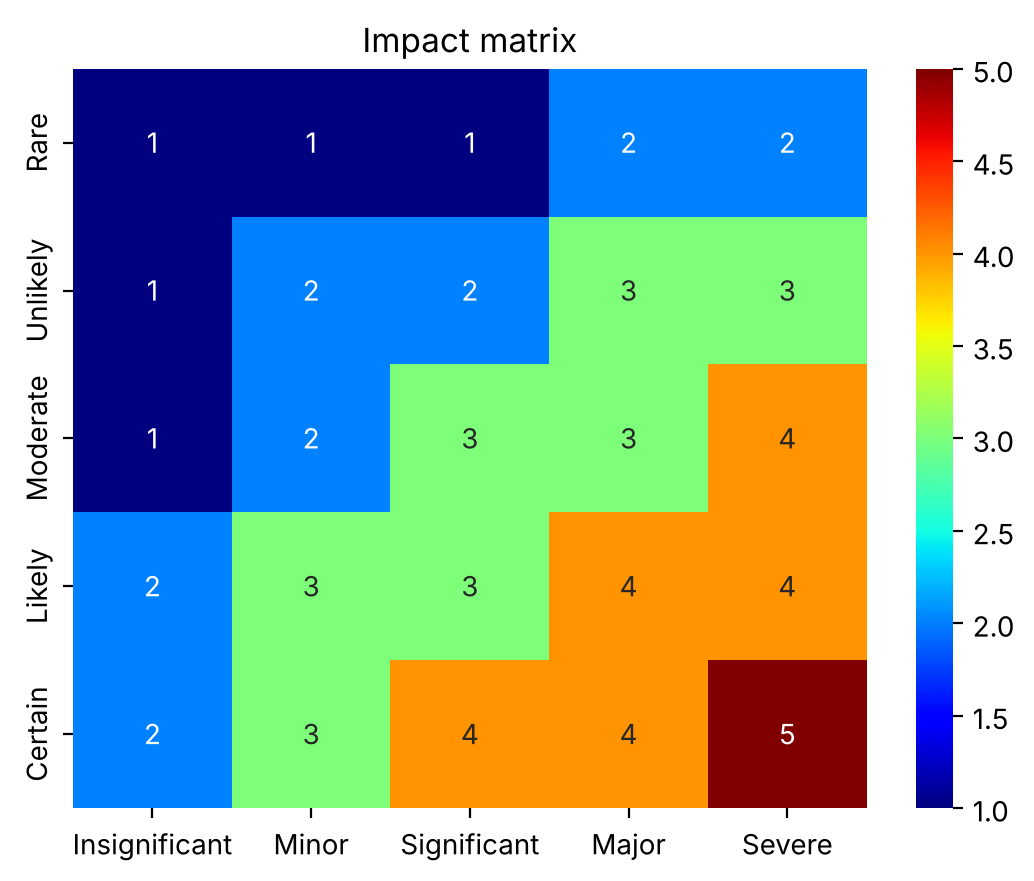

The loss with impact levels is (MCOP): 62.27710538823357


In [30]:
MI=np.array([[1,1,1,2,2],
             [1,2,2,3,3],
             [1,2,3,3,4],
             [2,3,3,4,4],
             [2,3,4,4,5]])

plt.figure()
sns.heatmap(MI,annot=True,fmt='.0f',cmap='jet',xticklabels=lbs,yticklabels=lbf)
plt.title('Impact matrix')
plt.show()

LDAm3=np.sum(MI*MP*MVP*ME)/np.sum(MVP*ME*MI)
print('The loss with impact levels is (MCOP):' ,LDAm3)

## 3.7 Management matrices and reference value

- Price of a tonne of CO₂: 80 USD/tonne (value from class) with an exchange rate of 3,200 COP/USD.
- Management cost per mobilized record (CGP): 10% of the average severity.

In [31]:
def management_matrix(MI,ng,kind):
  MG=MI.copy().astype(float)
  if kind=='Medium management (2-4)':
    MG[(MG>1)&(MG<5)]*=ng
  elif kind=='High management (4-5)':
    MG[MG>=4]*=ng
  elif kind=='Total management (1-5)':
    MG*=ng
  return MG

kinds=['Medium management (2-4)','High management (4-5)','Total management (1-5)']

TRM=3200              #COP/USD exchange rate (approx. October 2026)
CCO2=80*TRM/1e6       #Price of a tonne of CO2 in MCOP

MG=management_matrix(MI,1,kinds[0])
LDAm0=np.sum(MI*MP*MVP*ME)/np.sum(MVP*ME*MG)
print("The reference value is (NG = 1):" ,LDAm0)

The reference value is (NG = 1): 62.27710538823357


## 3.8 Management for the reference record

In [32]:
NG=1.5  #Management level for the reference record

for kind in kinds:
  print("----------------------")
  print(kind)
  MG=management_matrix(MI,NG,kind)
  print("The management matrix is:\n" ,MG)
  ER=np.mean(MI/MG)
  print("The risk exposure is:" ,ER)

  LDAm4=np.sum(MI*MP*MVP*ME)/np.sum(MVP*ME*MG)
  print(f'The loss with management {NG} is (MCOP):' ,LDAm4)

  VCapt=LDAm0-LDAm4
  print("The financial value captured is (MCOP):" ,VCapt)
  TC=VCapt/CCO2
  print("The tonnes captured are:" ,TC)

print("----------------------")
print('The traditional loss is (MCOP):' ,LDAr)
print('The loss with the membership matrix is (MCOP):' ,LDAm)
print('The loss with the event matrix is (MCOP):' ,LDAm2)
print('The loss with impact levels is (MCOP):' ,LDAm3)

----------------------
Medium management (2-4)
The management matrix is:
 [[1.  1.  1.  3.  3. ]
 [1.  3.  3.  4.5 4.5]
 [1.  3.  4.5 4.5 6. ]
 [3.  4.5 4.5 6.  6. ]
 [3.  4.5 6.  6.  5. ]]
The risk exposure is: 0.7466666666666666
The loss with management 1.5 is (MCOP): 45.042968561994684
The financial value captured is (MCOP): 17.23413682623889
The tonnes captured are: 67.32084697749566
----------------------
High management (4-5)
The management matrix is:
 [[1.  1.  1.  2.  2. ]
 [1.  2.  2.  3.  3. ]
 [1.  2.  3.  3.  6. ]
 [2.  3.  3.  6.  6. ]
 [2.  3.  6.  6.  7.5]]
The risk exposure is: 0.92
The loss with management 1.5 is (MCOP): 61.66071049134589
The financial value captured is (MCOP): 0.6163948968876838
The tonnes captured are: 2.407792565967515
----------------------
Total management (1-5)
The management matrix is:
 [[1.5 1.5 1.5 3.  3. ]
 [1.5 3.  3.  4.5 4.5]
 [1.5 3.  4.5 4.5 6. ]
 [3.  4.5 4.5 6.  6. ]
 [3.  4.5 6.  6.  7.5]]
The risk exposure is: 0.6666666666666667
The 

## A typical AndesMed day, with a base loss of 62.3 million COP (the loss with impact levels), and how much it would drop with each management matrix at level 1.5

* The management matrix shows where more is invested. Each matrix multiplies the impact levels it manages by 1.5: Medium changes levels 2 to 4 (for example, 2 becomes 3 and 4 becomes 6), High only levels 4 and 5, and Total all of them.

* Risk exposure says what share of the risk remains after management (1 = all the risk remains). It's 0.75 with Medium, 0.92 with High and 0.67 with Total.

* The day's loss falls from 62.3 million to 45.0 with Medium management, to 61.7 with High and to 41.5 with Total.

* The value captured is what's saved that day: 17.2 million with Medium, 0.6 with High and 20.8 with Total.

* The tonnes of CO₂ captured that day are 67 with Medium, 2 with High and 81 with Total. They come from dividing the savings by the price per tonne: 80 dollars per tonne with an exchange rate of 3,200, that is, 0.256 million COP per tonne.

## What it means for the business

* On a normal day, Total and Medium management save the most. Total reduces the loss by 33% and Medium by 28%. The difference between them is small (3.5 million), and Medium doesn't spend on level-1 scenarios, which basic controls already handle.

* High management barely changes a normal day, because a typical day has almost no level 4 and 5 scenarios. Its value is on serious days, as the foresight section shows, where it's the only one that reduces skewness.

* This is the result for a single day. If management is sustained over time, the savings and the CO₂ captured add up day after day, which is what section 4 measures over the 1,000 days.

* The four losses at the end confirm the baseline: the traditional calculation (56.7 million) underestimates the real risk-adjusted loss (62.3 million) by 10%.

# 4. Foresight – loss distribution and GHG capture

Medium management (2-4)
----------------------
The management level is: 1.0
The risk exposure is: 1.0
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 62.278364819267665
Managed loss events: 570
Managed skewness coefficient: 6.177395639504432
Number of loss events mobilized: 0
The financial value captured is (MCOP): 0.0
The tonnes captured are: 0.0
The management cost of the mobilized events is (MCOP): 0.0
The net benefit is (MCOP): 0.0
----------------------
The management level is: 1.1
The risk exposure is: 0.9309090909090909
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 57.85379607250924
Managed loss events: 862
Managed skewness coefficient: 6.26910122016358
Number of loss events mobilized: 292
The financial value captured is (MCOP): 609.4871645200001
The tonnes captured are: 2380.8092364062504
The management cost of the mobilized events is (MCOP): 60.94871645200001
The net

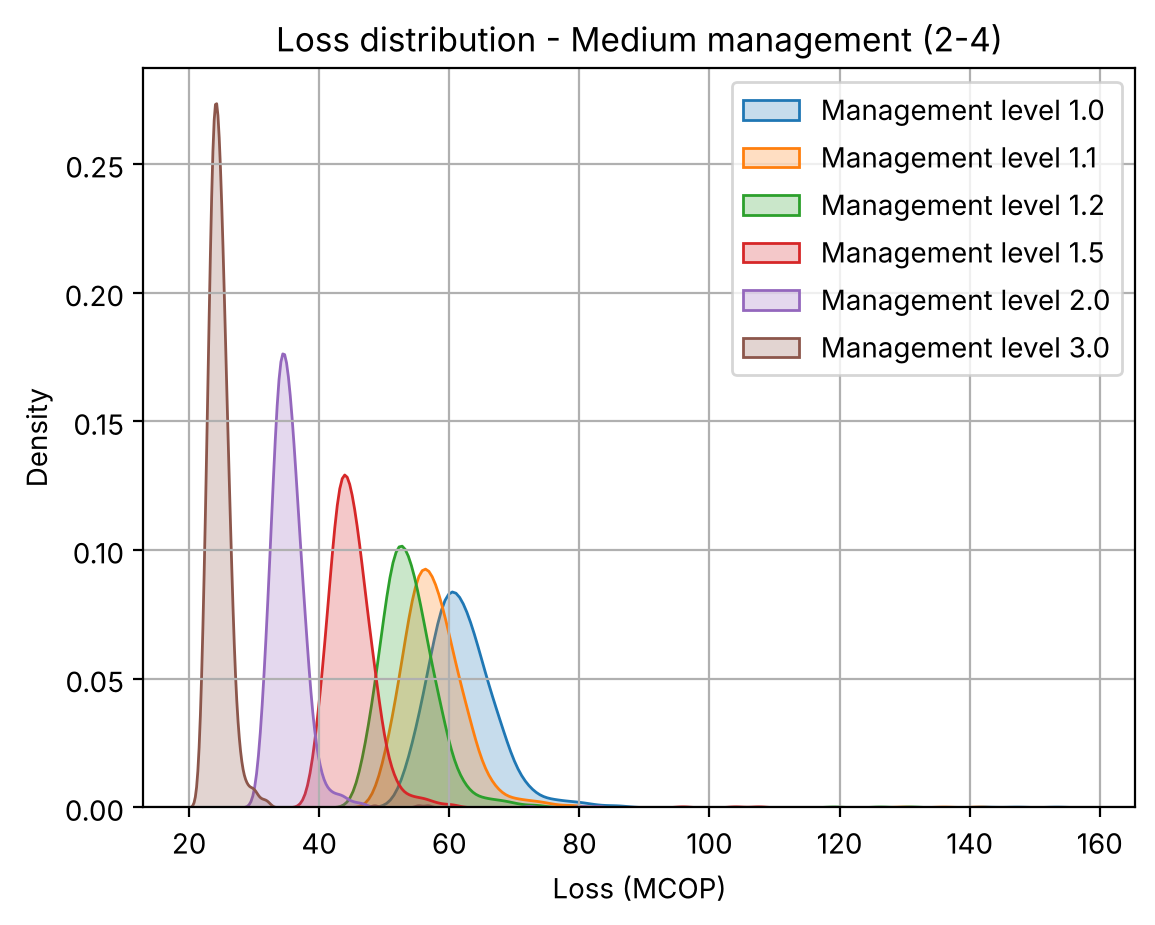

High management (4-5)
----------------------
The management level is: 1.0
The risk exposure is: 1.0
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 62.278364819267665
Managed loss events: 570
Managed skewness coefficient: 6.177395639504432
Number of loss events mobilized: 0
The financial value captured is (MCOP): 0.0
The tonnes captured are: 0.0
The management cost of the mobilized events is (MCOP): 0.0
The net benefit is (MCOP): 0.0
----------------------
The management level is: 1.1
The risk exposure is: 0.9781818181818183
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 62.13845586172021
Managed loss events: 582
Managed skewness coefficient: 5.831126157609332
Number of loss events mobilized: 12
The financial value captured is (MCOP): 25.047417720000006
The tonnes captured are: 97.84147546875002
The management cost of the mobilized events is (MCOP): 2.5047417720000005
The net 

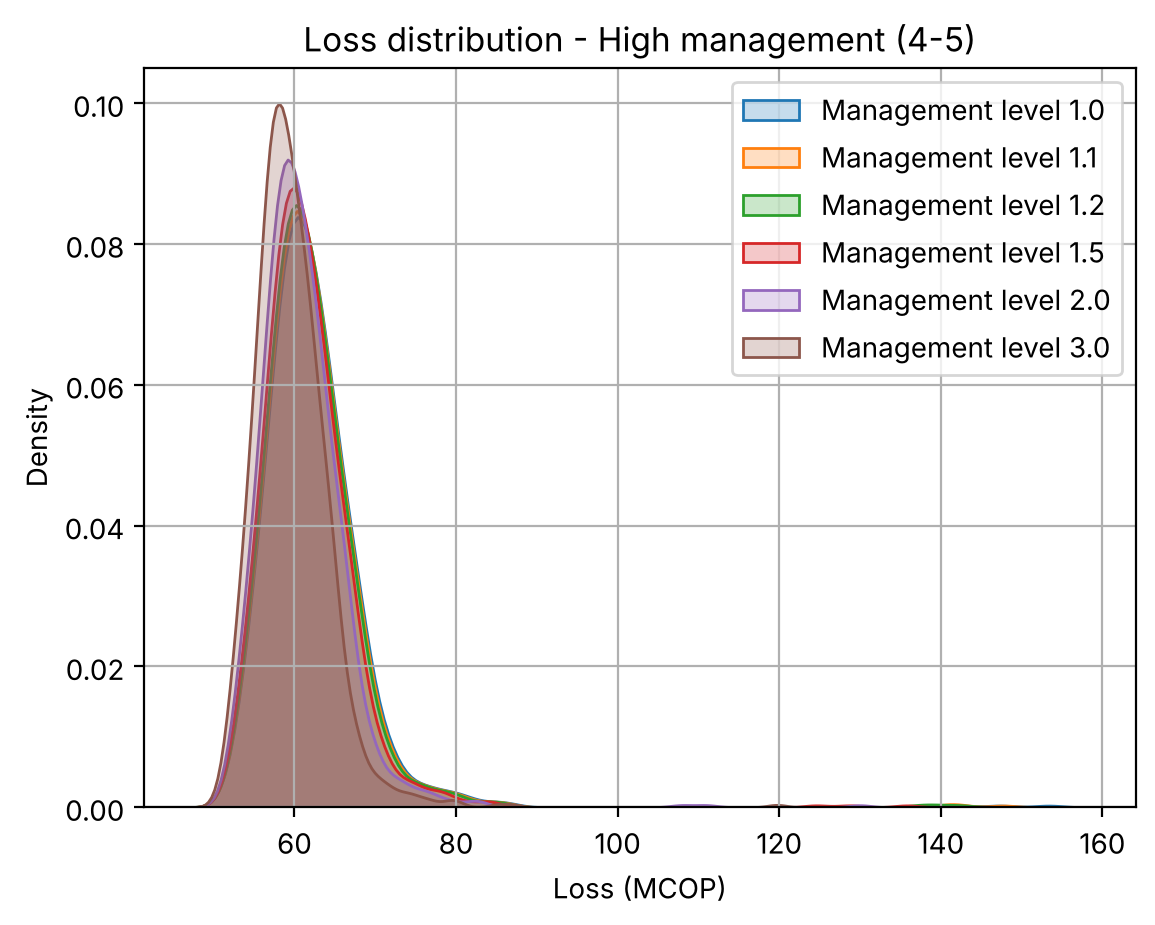

Total management (1-5)
----------------------
The management level is: 1.0
The risk exposure is: 1.0
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 62.278364819267665
Managed loss events: 570
Managed skewness coefficient: 6.177395639504432
Number of loss events mobilized: 0
The financial value captured is (MCOP): 0.0
The tonnes captured are: 0.0
The management cost of the mobilized events is (MCOP): 0.0
The net benefit is (MCOP): 0.0
----------------------
The management level is: 1.1
The risk exposure is: 0.9090909090909091
Reference loss events: 570
Reference skewness coefficient: 6.177395639504432
Mean managed loss (MCOP): 56.61669529024332
Managed loss events: 914
Managed skewness coefficient: 6.1773956395044385
Number of loss events mobilized: 344
The financial value captured is (MCOP): 718.0259746400001
The tonnes captured are: 2804.7889634375
The management cost of the mobilized events is (MCOP): 71.80259746400002
The net b

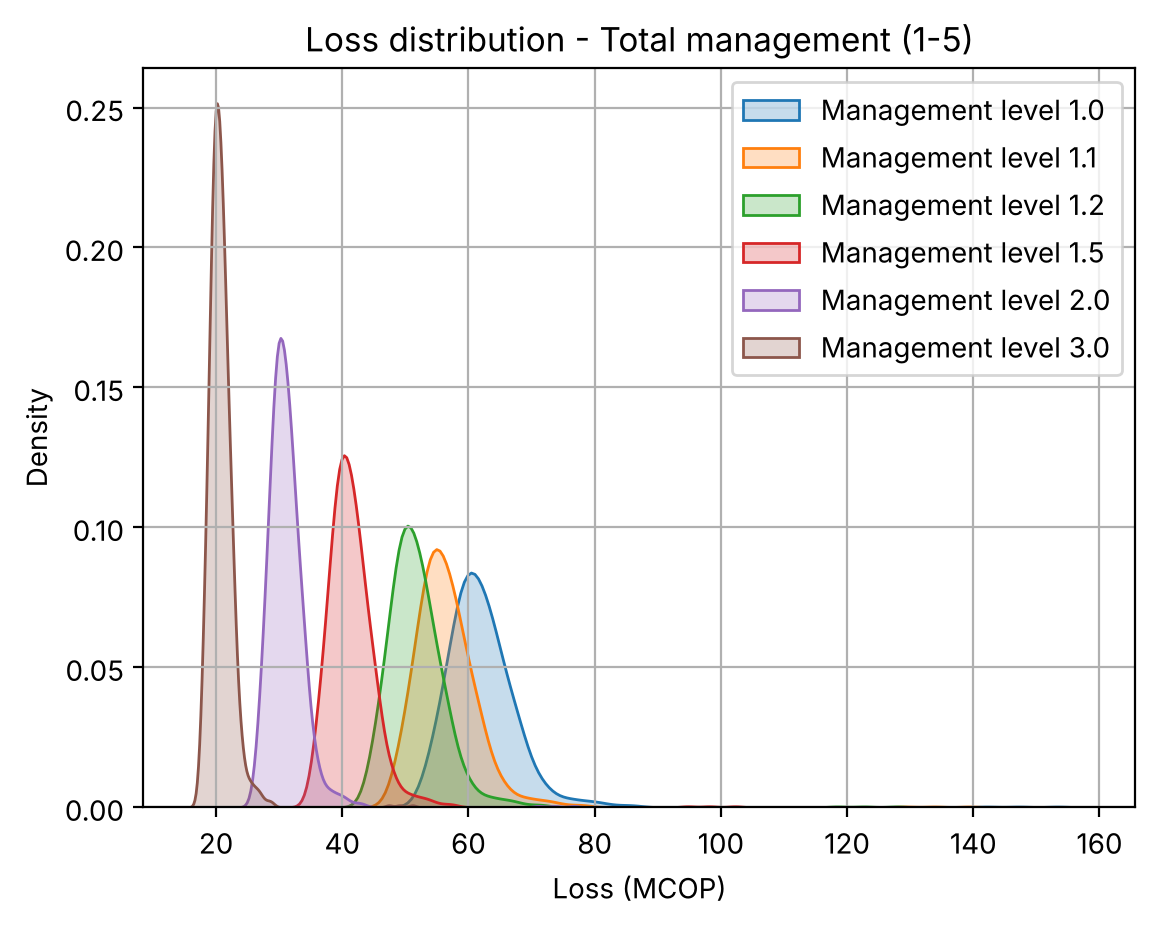

In [33]:
NG=np.array([1,1.1,1.2,1.5,2,3])
CPerd=np.mean(Xs)   #Cost of an average loss (MCOP)
CGP=0.10*CPerd      #Management cost per mobilized record (assumption)

for kind in kinds:
  print("======================")
  print(kind)
  plt.figure()

  for ng in NG:
    print("----------------------")
    print("The management level is:" ,ng)

    MG=management_matrix(MI,ng,kind)
    ER=np.mean(MI/MG)
    print("The risk exposure is:" ,ER)

    LDAm5=[]
    for k in range(len(XDBi)):
      VPf=np.exp(-0.5*((XCf-Xf[k])/sigmaf)**2)
      VPs=np.exp(-0.5*((XCs-Xs[k])/sigmas)**2)
      MVPk=np.outer(VPf,VPs)   #Different name so the reference MVP isn't overwritten
      LDAm5.append(np.sum(MI*MP*MVPk*ME)/np.sum(MVPk*ME*MG))

    LDAm5=np.array(LDAm5)

    if ng==1:
      LDAm0ref=LDAm5

    um0=np.mean(LDAm0ref)
    NEL0=len(np.where(LDAm0ref<um0)[0])
    CAS0=stats.skew(LDAm0ref)
    print("Reference loss events:" ,NEL0)
    print("Reference skewness coefficient:" ,CAS0)

    umg=np.mean(LDAm5)
    NELg=len(np.where(LDAm5<um0)[0])  #Compared against the REFERENCE mean
    CASg=stats.skew(LDAm5)
    print("Mean managed loss (MCOP):" ,umg)
    print("Managed loss events:" ,NELg)
    print("Managed skewness coefficient:" ,CASg)

    NEPm=NELg-NEL0
    print("Number of loss events mobilized:" ,NEPm)

    VCapt=NEPm*CPerd
    print("The financial value captured is (MCOP):" ,VCapt)
    TC=VCapt/CCO2
    print("The tonnes captured are:" ,TC)
    CGT=NEPm*CGP
    print("The management cost of the mobilized events is (MCOP):" ,CGT)
    print("The net benefit is (MCOP):" ,VCapt-CGT)

    sns.kdeplot(LDAm5,fill=True,label=f'Management level {ng}')

  plt.title(f'Loss distribution - {kind}')
  plt.xlabel('Loss (MCOP)')
  plt.legend()
  plt.grid()
  plt.show()

## Medium management (levels 2 to 4)
* Mean loss: falls from 62.3 to 45.1 million at level 1.5 (−28%) and to 24.6 million at level 3.

* Days mobilized: 292 at level 1.1, 394 at level 1.2 and 427 at level 1.5. It stays at 427 at level 2 and reaches 430 at level 3.

* At level 1.5: 891 million in value captured, 802 million in net benefit and 3,482 tonnes of CO₂.

* Skewness: rises from 6.18 to 7.34. Most days become cheap, but the extreme days are left relatively behind.

## High management (levels 4 and 5)
* Mean loss: barely changes, from 62.3 to 61.6 million at level 1.5 and to 59.7 at level 3.

* Days mobilized: few, but they keep growing: 57 at level 1.5, 99 at level 2 and 203 at level 3.

* At level 3: 424 million in value captured and 1,655 tonnes of CO₂.

* Skewness: falls from 6.18 to 2.98 at level 3. It's the only matrix that trims the extreme days.

## Total management (levels 1 to 5)
* Mean loss: falls the most, to 41.5 million at level 1.5 (−33%) and to 20.8 at level 3.

* Days mobilized: 344 at level 1.1 and 427 at level 1.5, the same as Medium management. The result in days, value and CO₂ at level 1.5 is identical to Medium's.

* Skewness: stays at 6.18 at every level. Because it reduces every scenario equally, the shape of the distribution doesn't change, it just gets smaller.

## Conclusions
1. The optimal level is 1.5. With Medium or Total management, 427 of the 430 possible days are mobilized. Going to level 2 or 3 lowers the mean loss, but adds no days mobilized, value captured or CO₂. Investing beyond 1.5 isn't justified.

2. Medium management is the most efficient. It achieves the same result as Total at level 1.5 (3,482 tonnes of CO₂ and 802 million in net benefit), without spending on level-1 scenarios, which basic measures already control.

3. High management is insurance against extreme days. It saves little on average, but it's the only one that reduces skewness, to less than half. It's the ideal complement for refrigeration failures in trucks and on long routes.

***Recommendation:*** apply Medium management at level 1.5 as the baseline and complement it with High management to protect AndesMed from its costliest days.